#Proyecto de aula - Parte 3


#Descripción de la base de datos

##Identificación

| Atributo | Detalle |
|---|---|
| **Nombre** | S&P 500 Companies with Financial Information |
| **Fuente** | Kaggle — publicado por Payton Fisher (2020). Los datos provienen originalmente de la lista de constituyentes del S&P 500 y de métricas de mercado de Yahoo Finance. |
| **Enlace** | https://www.kaggle.com/datasets/paytonfisher/sp-500-companies-with-financial-information |
| **Observaciones** | 505 registros (una fila por acción del índice) |
| **Columnas** | 14 |
| **Unidad de análisis** | Una empresa (acción) que hace parte del índice S&P 500 |
| **Corte temporal** | Datos de corte transversal: una sola fotografía de las métricas en el momento de la recolección, no una serie de tiempo |

> **Nota:** el índice tiene 500 empresas pero el archivo tiene 505 filas porque algunas compañías cotizan con más de una clase de acción (por ejemplo, Alphabet con GOOGL y GOOG).

##Dominio del problema

El **S&P 500** es un índice ponderado por capitalización bursátil que agrupa a las 500 empresas más grandes que cotizan en las bolsas de Estados Unidos. Es la referencia más usada para medir el desempeño del mercado accionario estadounidense y sirve de *benchmark* para buena parte de la industria de gestión de activos.

Cada empresa del índice está clasificada según el **GICS** (*Global Industry Classification Standard*), un estándar desarrollado por MSCI y S&P Dow Jones Indices. El GICS organiza a las compañías en una jerarquía de cuatro niveles: sector, grupo de industria, industria y sub-industria. Esta base de datos usa el **primer nivel: 11 sectores**, por ejemplo Tecnología de la Información, Financiero, Salud, Energía o Servicios Públicos (*Utilities*).

Junto a la clasificación sectorial, la base trae **métricas financieras y de valoración** de cada empresa: múltiplos como P/E, P/S y P/B, rentabilidad (EBITDA, utilidad por acción), tamaño (capitalización de mercado), política de dividendos (dividend yield) y comportamiento del precio (mínimo y máximo de 52 semanas).

El dominio es, por tanto, el **análisis fundamental y la valoración relativa de empresas**: los indicadores que usan analistas e inversionistas para comparar compañías entre sí.

##Utilidad y pregunta de investigación

En finanzas, la clasificación sectorial es fundamental para:

- **Valoración por comparables (*trading comps*):** para valorar una empresa con múltiplos se necesita un grupo de pares comparables, y tradicionalmente ese grupo se define por sector.
- **Construcción de portafolios:** la diversificación sectorial y las estrategias *sector-neutral* dependen de cómo se agrupan las empresas.
- **Gestión de riesgo:** las empresas de un mismo sector tienden a responder de forma parecida a los mismos choques (precio del petróleo, tasas de interés, ciclo económico).

Sin embargo, la clasificación GICS se basa en **la actividad económica** de la empresa (qué produce o qué servicio presta) y no en su **perfil financiero**. Eso abre la pregunta central de este proyecto:

> **¿Las métricas financieras y de valoración, por sí solas, contienen suficiente información para reconstruir los sectores económicos sin conocerlos de antemano?**

Si los algoritmos de agrupamiento logran recuperar los sectores, significa que cada sector tiene una "huella financiera" distintiva. Si no lo logran, los grupos que sí encuentren pueden ser igualmente útiles, por ejemplo empresas *value* frente a *growth*, o de alto dividendo frente a alto crecimiento, y pueden servir como una **segmentación alternativa** basada en características financieras y no en industria.

##Variables del modelo

### Variables de identificación (no se usan en el modelado)

| Variable | Tipo | Descripción |
|---|---|---|
| `Symbol` | Texto | *Ticker* o símbolo bursátil de la acción (ej. AAPL, MSFT) |
| `Name` | Texto | Nombre de la empresa |
| `SEC Filings` | Texto (URL) | Enlace a los reportes de la empresa ante la SEC (*Securities and Exchange Commission*) |

### Variable de salida

| Variable | Tipo | Descripción |
|---|---|---|
| `Sector` | Categórica nominal (11 clases) | Sector económico de la empresa según el primer nivel de la clasificación GICS |

### Variables de entrada (características financieras)

| Variable | Tipo | Unidad | Descripción e interpretación financiera |
|---|---|---|---|
| `Price` | Numérica continua | USD | Precio de la acción. Por sí solo no tiene significado económico comparativo, porque depende del número de acciones que haya emitido la empresa |
| `Price/Earnings` | Numérica continua (razón) | Veces | **P/E**: precio dividido entre la utilidad por acción. Indica cuántas veces paga el mercado las utilidades anuales. Un P/E alto suele asociarse a expectativas de crecimiento (*growth*) y uno bajo a empresas maduras (*value*) |
| `Dividend Yield` | Numérica continua (proporción) | Proporción (0.03 = 3%) | Dividendos anuales por acción divididos entre el precio. Alto en sectores maduros y regulados (*Utilities*, *Real Estate*) y bajo o nulo en empresas de crecimiento |
| `Earnings/Share` | Numérica continua | USD por acción | **EPS**: utilidad neta dividida entre el número de acciones. Puede ser negativa si la empresa tuvo pérdidas |
| `52 Week Low` | Numérica continua | USD | Precio mínimo de la acción en las últimas 52 semanas |
| `52 Week High` | Numérica continua | USD | Precio máximo de la acción en las últimas 52 semanas |
| `Market Cap` | Numérica continua | USD | **Capitalización bursátil**: precio multiplicado por el número de acciones en circulación. Mide el tamaño de la empresa según el mercado |
| `EBITDA` | Numérica continua | USD | Utilidad antes de intereses, impuestos, depreciación y amortización. *Proxy* de la generación operativa de caja. Puede ser negativa |
| `Price/Sales` | Numérica continua (razón) | Veces | **P/S**: capitalización dividida entre las ventas anuales. Útil para valorar empresas con utilidades bajas o negativas |
| `Price/Book` | Numérica continua (razón) | Veces | **P/B**: precio dividido entre el valor en libros (patrimonio contable) por acción. Alto en empresas con activos intangibles (tecnología) y cercano a 1 en bancos. Puede ser negativo si la empresa tiene patrimonio contable negativo |

**Resumen:** 10 variables numéricas continuas, 1 variable categórica de salida y 3 variables de identificación.

##Tipo de problema

**En su formulación original**, la base de datos corresponde a un problema de **aprendizaje supervisado de clasificación multiclase**: dado el perfil financiero de una empresa, predecir a cuál de los 11 sectores GICS pertenece.

**En este proyecto**, el problema se aborda con **aprendizaje no supervisado (agrupamiento o *clustering*)**:

1. Se **excluye la variable `Sector`** durante el entrenamiento. Los algoritmos solo ven las métricas financieras.
2. Se aplican tres métodos de agrupamiento: **K-means**, **clustering jerárquico aglomerativo** y **DBSCAN**.
3. Se prueban distintos números de grupos, incluido **k = 11** (el número real de sectores).
4. Al final, la variable `Sector` se usa **solo como referencia externa** para evaluar qué tanto se parecen los grupos encontrados a los sectores reales, mediante métricas como el **Adjusted Rand Index (ARI)** y la **Normalized Mutual Information (NMI)**.

In [ ]:
import os
import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import (silhouette_score, adjusted_rand_score, normalized_mutual_info_score,
                             homogeneity_score, completeness_score, accuracy_score)

from scipy.cluster.hierarchy import dendrogram, linkage, fcluster, cophenet
from scipy.spatial.distance import pdist

sns.set(style="whitegrid")

In [ ]:
import kagglehub, os
import pandas as pd

path = kagglehub.dataset_download("paytonfisher/sp-500-companies-with-financial-information")
print(os.listdir(path))   # para ver el nombre exacto del CSV

df = pd.read_csv(os.path.join(path, "financials.csv"))
df.shape

Using Colab cache for faster access to the 'sp-500-companies-with-financial-information' dataset.
['financials.csv']


(505, 14)

In [ ]:
#Primera vista del dataset
df.head()

,Symbol,Name,Sector,Price,Price/Earnings,Dividend Yield,Earnings/Share,52 Week Low,52 Week High,Market Cap,EBITDA,Price/Sales,Price/Book,SEC Filings
0,MMM,3M Company,Industrials,222.89,24.31,2.332862,7.92,259.77,175.490,1.387211e+11,9.048000e+09,4.390271,11.34,http://www.sec.gov/cgi-bin/browse-edgar?action...
1,AOS,A.O. Smith Corp,Industrials,60.24,27.76,1.147959,1.70,68.39,48.925,1.078342e+10,6.010000e+08,3.575483,6.35,http://www.sec.gov/cgi-bin/browse-edgar?action...
2,ABT,Abbott Laboratories,Health Care,56.27,22.51,1.908982,0.26,64.60,42.280,1.021210e+11,5.744000e+09,3.740480,3.19,http://www.sec.gov/cgi-bin/browse-edgar?action...
3,ABBV,AbbVie Inc.,Health Care,108.48,19.41,2.499560,3.29,125.86,60.050,1.813863e+11,1.031000e+10,6.291571,26.14,http://www.sec.gov/cgi-bin/browse-edgar?action...
4,ACN,Accenture plc,Information Technology,150.51,25.47,1.714470,5.44,162.60,114.820,9.876586e+10,5.643228e+09,2.604117,10.62,http://www.sec.gov/cgi-bin/browse-edgar?action...


#Analisis exploratorio de datos

Se elimina la variable SEC Filings porque es un enlace web y no aporta información. Symbol y Name se conservan para identificar a qué cluster pertenece cada empresa, pero no entran a los modelos.

In [ ]:
df.drop(columns=['SEC Filings'], inplace=True)
df.head()

,Symbol,Name,Sector,Price,Price/Earnings,Dividend Yield,Earnings/Share,52 Week Low,52 Week High,Market Cap,EBITDA,Price/Sales,Price/Book
0,MMM,3M Company,Industrials,222.89,24.31,2.332862,7.92,259.77,175.490,1.387211e+11,9.048000e+09,4.390271,11.34
1,AOS,A.O. Smith Corp,Industrials,60.24,27.76,1.147959,1.70,68.39,48.925,1.078342e+10,6.010000e+08,3.575483,6.35
2,ABT,Abbott Laboratories,Health Care,56.27,22.51,1.908982,0.26,64.60,42.280,1.021210e+11,5.744000e+09,3.740480,3.19
3,ABBV,AbbVie Inc.,Health Care,108.48,19.41,2.499560,3.29,125.86,60.050,1.813863e+11,1.031000e+10,6.291571,26.14
4,ACN,Accenture plc,Information Technology,150.51,25.47,1.714470,5.44,162.60,114.820,9.876586e+10,5.643228e+09,2.604117,10.62


In [ ]:
# Tipos de datos y conteo de nulos
info = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "n_nulls": df.isna().sum(),
    "n_unique": df.nunique()
}).sort_index()

display(info)
display(df.describe())

,dtype,n_nulls,n_unique
52 Week High,float64,0,495
52 Week Low,float64,0,501
Dividend Yield,float64,0,420
EBITDA,float64,0,444
Earnings/Share,float64,0,402
Market Cap,float64,0,505
Name,object,0,505
Price,float64,0,494
Price/Book,float64,8,391
Price/Earnings,float64,2,457


,Price,Price/Earnings,Dividend Yield,Earnings/Share,52 Week Low,52 Week High,Market Cap,EBITDA,Price/Sales,Price/Book
count,505.000000,503.000000,505.000000,505.000000,505.000000,505.000000,5.050000e+02,5.050000e+02,505.000000,497.000000
mean,103.830634,24.808390,1.895953,3.753743,122.623832,83.536616,4.923944e+10,3.590328e+09,3.941705,14.453179
std,134.427636,41.241081,1.537214,5.689036,155.362140,105.725473,9.005017e+10,6.840544e+09,3.460110,89.660508
min,2.820000,-251.530000,0.000000,-28.010000,6.590000,2.800000,2.626102e+09,-5.067000e+09,0.153186,0.510000
25%,46.250000,15.350000,0.794834,1.490000,56.250000,38.430000,1.273207e+10,7.739320e+08,1.629490,2.020000
50%,73.920000,19.450000,1.769255,2.890000,86.680000,62.850000,2.140095e+10,1.614399e+09,2.896440,3.400000
75%,116.540000,25.750000,2.781114,5.140000,140.130000,96.660000,4.511968e+10,3.692749e+09,4.703842,6.110000
max,1806.060000,520.150000,12.661196,44.090000,2067.990000,1589.000000,8.095080e+11,7.938600e+10,20.094294,1403.380000


### Análisis preliminar de las variables

- **Tipos de variable:** 3 columnas de texto (`Symbol`, `Name` y `Sector`, esta última categórica nominal con 11 clases) y 10 variables numéricas continuas (`float64`).
- **Valores nulos:** solo en `Price/Earnings` (2) y `Price/Book` (8), es decir, 10 valores en total. Se imputan más adelante.
- **Escalas muy distintas.** Las variables numéricas forman tres grupos:
    - *Niveles de precio por acción (USD):* `Price` va de 2,82 a 1.806 USD, y las variables de 52 semanas tienen rangos similares.
    - *Montos absolutos (USD):* `Market Cap` va de 2.626 millones a 809.508 millones de USD, y `EBITDA` de −5.067 millones a 79.386 millones de USD.
    - *Razones y porcentajes:* `Price/Earnings`, `Price/Sales` y `Price/Book` se expresan en veces, y `Dividend Yield` en porcentaje (de 0% a 12,66%).
- **Valores extremos:** el P/E va de −251,5 a 520,2 con mediana de 19,5, y el P/B va de 0,51 a 1.403 con mediana de 3,4. En P/B, la media (14,5) es más de cuatro veces la mediana, lo que evidencia una cola derecha muy larga.
- **Valores negativos con significado económico:** 51 empresas tienen EPS negativo (registraron pérdidas) y el EBITDA mínimo es negativo.
- **Ceros con significado económico:** 86 empresas tienen `Dividend Yield` = 0 porque no pagan dividendo. Además, 58 empresas tienen `EBITDA` = 0, y 51 de ellas son del sector financiero: el EBITDA no se calcula para bancos y aseguradoras, por lo que la fuente les asigna 0. No es un dato faltante, pero sí un artefacto de la fuente que conviene tener presente al interpretar los grupos.

Al observar la descripcion de las medidas estadisticas de los datos, se identificaron inconsistencias en las variables 52 Week Low y 52 Week High, los nombres de las variables estan invertidas entre sí, se confirma con el siguiente codigo:

In [ ]:
print(df[["Price", "52 Week Low", "52 Week High"]].head())
print("Filas con Low > High:", (df["52 Week Low"] > df["52 Week High"]).mean() * 100, "%")

    Price  52 Week Low  52 Week High
0  222.89       259.77       175.490
1   60.24        68.39        48.925
2   56.27        64.60        42.280
3  108.48       125.86        60.050
4  150.51       162.60       114.820
Filas con Low > High: 100.0 %


In [ ]:
#Por lo cual se realiza la corrección de los datos:
# Corrección: en este dataset las columnas de 52 semanas vienen intercambiadas
df = df.rename(columns={"52 Week Low": "52 Week High", "52 Week High": "52 Week Low"})

In [ ]:
# Limpieza mínima: eliminar duplicados exactos si existieran
n_before = len(df)
df = df.drop_duplicates()
n_after = len(df)
print(f"Filas eliminadas por duplicados: {n_before - n_after}")
df.head()

Filas eliminadas por duplicados: 0


,Symbol,Name,Sector,Price,Price/Earnings,Dividend Yield,Earnings/Share,52 Week High,52 Week Low,Market Cap,EBITDA,Price/Sales,Price/Book
0,MMM,3M Company,Industrials,222.89,24.31,2.332862,7.92,259.77,175.490,1.387211e+11,9.048000e+09,4.390271,11.34
1,AOS,A.O. Smith Corp,Industrials,60.24,27.76,1.147959,1.70,68.39,48.925,1.078342e+10,6.010000e+08,3.575483,6.35
2,ABT,Abbott Laboratories,Health Care,56.27,22.51,1.908982,0.26,64.60,42.280,1.021210e+11,5.744000e+09,3.740480,3.19
3,ABBV,AbbVie Inc.,Health Care,108.48,19.41,2.499560,3.29,125.86,60.050,1.813863e+11,1.031000e+10,6.291571,26.14
4,ACN,Accenture plc,Information Technology,150.51,25.47,1.714470,5.44,162.60,114.820,9.876586e+10,5.643228e+09,2.604117,10.62


In [ ]:
# Columnas numéricas (excluye Symbol, Name, Sector, SEC Filings)
num_cols = df.select_dtypes(include="number").columns.tolist()

#Diagnóstico antes de imputar
nulos = df[num_cols].isna().sum()
print("Nulos por variable:\n", nulos[nulos > 0])
print("\nTotal de nulos:", nulos.sum())

# Guardar las filas con nulos antes de imputar (se usa más adelante)
filas_con_nulos = df[df[num_cols].isna().any(axis=1)]

Nulos por variable:
 Price/Earnings    2
Price/Book        8
dtype: int64

Total de nulos: 10


In [ ]:
# Comparación de media y mediana para elegir el valor de imputación
print(df[num_cols].agg(["mean", "median"]).T.round(3))

# Imputación con la mediana directamente sobre df
medianas = df[num_cols].median()
df[num_cols] = df[num_cols].fillna(medianas)

print("\nValores imputados:")
print(medianas[nulos > 0].round(3))
print("\nNulos después de imputar:", df[num_cols].isna().sum().sum())

                        mean        median
Price           1.038310e+02  7.392000e+01
Price/Earnings  2.480800e+01  1.945000e+01
Dividend Yield  1.896000e+00  1.769000e+00
Earnings/Share  3.754000e+00  2.890000e+00
52 Week High    1.226240e+02  8.668000e+01
52 Week Low     8.353700e+01  6.285000e+01
Market Cap      4.923944e+10  2.140095e+10
EBITDA          3.590328e+09  1.614399e+09
Price/Sales     3.942000e+00  2.896000e+00
Price/Book      1.445300e+01  3.400000e+00

Valores imputados:
Price/Earnings    19.45
Price/Book         3.40
dtype: float64

Nulos después de imputar: 0


Se imputa con la mediana porque las variables con nulos presentan distribuciones muy asimétricas: en Price/Book la media (14,45) es más de cuatro veces la mediana (3,40) por efecto de valores extremos, y la mediana no se ve afectada por ellos.

                            Empresas  Porcentaje (%)
Sector                                              
Consumer Discretionary            84           16.63
Information Technology            70           13.86
Financials                        68           13.47
Industrials                       67           13.27
Health Care                       61           12.08
Consumer Staples                  34            6.73
Real Estate                       33            6.53
Energy                            32            6.34
Utilities                         28            5.54
Materials                         25            4.95
Telecommunication Services         3            0.59

Número de clases: 11
Razón de desbalance (mayor / menor): 28.0


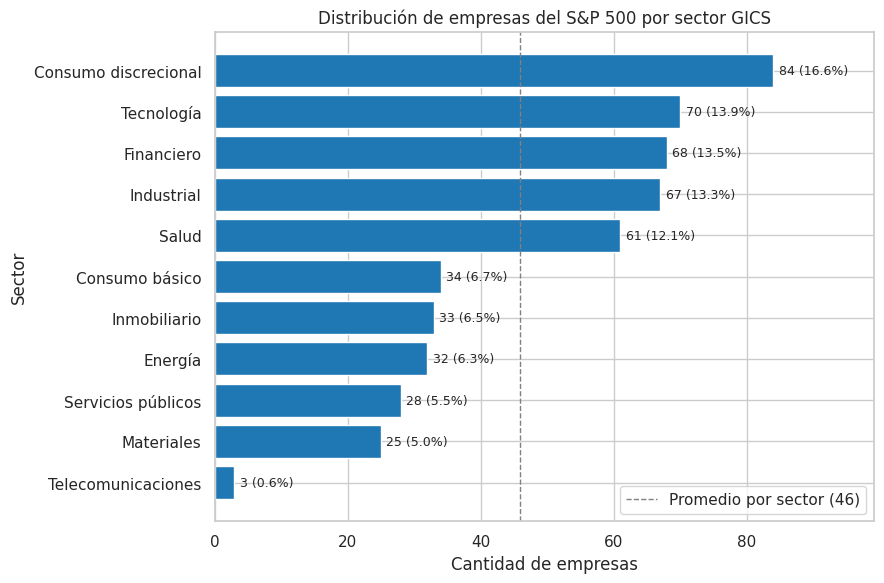

In [ ]:
import matplotlib.pyplot as plt

#Análisis de la etiqueta: Sector

# Conteo absoluto y proporcional
conteo = df["Sector"].value_counts()               # ordenado de mayor a menor
proporcion = df["Sector"].value_counts(normalize=True) * 100

resumen = pd.DataFrame({"Empresas": conteo, "Porcentaje (%)": proporcion.round(2)})
print(resumen)
print("\nNúmero de clases:", df["Sector"].nunique())
print("Razón de desbalance (mayor / menor):", round(conteo.max() / conteo.min(), 2))

# Traducción de los sectores para el gráfico
etiquetas = {
    "Industrials": "Industrial",
    "Financials": "Financiero",
    "Information Technology": "Tecnología",
    "Health Care": "Salud",
    "Consumer Discretionary": "Consumo discrecional",
    "Consumer Staples": "Consumo básico",
    "Utilities": "Servicios públicos",
    "Real Estate": "Inmobiliario",
    "Materials": "Materiales",
    "Energy": "Energía",
    "Communication Services": "Servicios de comunicación",
    "Telecommunication Services": "Telecomunicaciones",
}

# Gráfico de barras horizontales (de menor a mayor para que la más grande quede arriba)
conteo_plot = conteo.sort_values()
nombres = conteo_plot.index.map(lambda s: etiquetas.get(s, s))

fig, ax = plt.subplots(figsize=(9, 6))
barras = ax.barh(nombres, conteo_plot.values, color="#1f77b4")

# Etiqueta con cantidad y porcentaje al final de cada barra
for barra, n in zip(barras, conteo_plot.values):
    ax.text(barra.get_width() + 0.8, barra.get_y() + barra.get_height() / 2,
            f"{n} ({n / conteo.sum() * 100:.1f}%)", va="center", fontsize=9)

ax.axvline(conteo.mean(), color="gray", linestyle="--", linewidth=1,
           label=f"Promedio por sector ({conteo.mean():.0f})")
ax.set_title("Distribución de empresas del S&P 500 por sector GICS")
ax.set_xlabel("Cantidad de empresas")
ax.set_ylabel("Sector")
ax.set_xlim(0, conteo.max() * 1.18)
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

**Análisis de la variable de salida.** El dataset tiene 11 clases desbalanceadas. *Consumer Discretionary* es la más numerosa (84 empresas, 16,6%) y *Telecommunication Services* la más pequeña (3 empresas, 0,6%), lo que produce una razón de desbalance de 28:1. Sin el sector de telecomunicaciones, el rango va de 84 a 25 empresas (3,4:1).

Esto tiene dos consecuencias para el proyecto:

- Un modelo que asignara todas las empresas al sector más grande acertaría el 16,6% de las veces. Esa es la **línea base** contra la cual se comparan los modelos en la sección 6.
- Con solo 3 empresas, *Telecommunication Services* difícilmente podrá formar un grupo propio en ningún algoritmo, lo que penaliza por igual las métricas de todos los modelos.

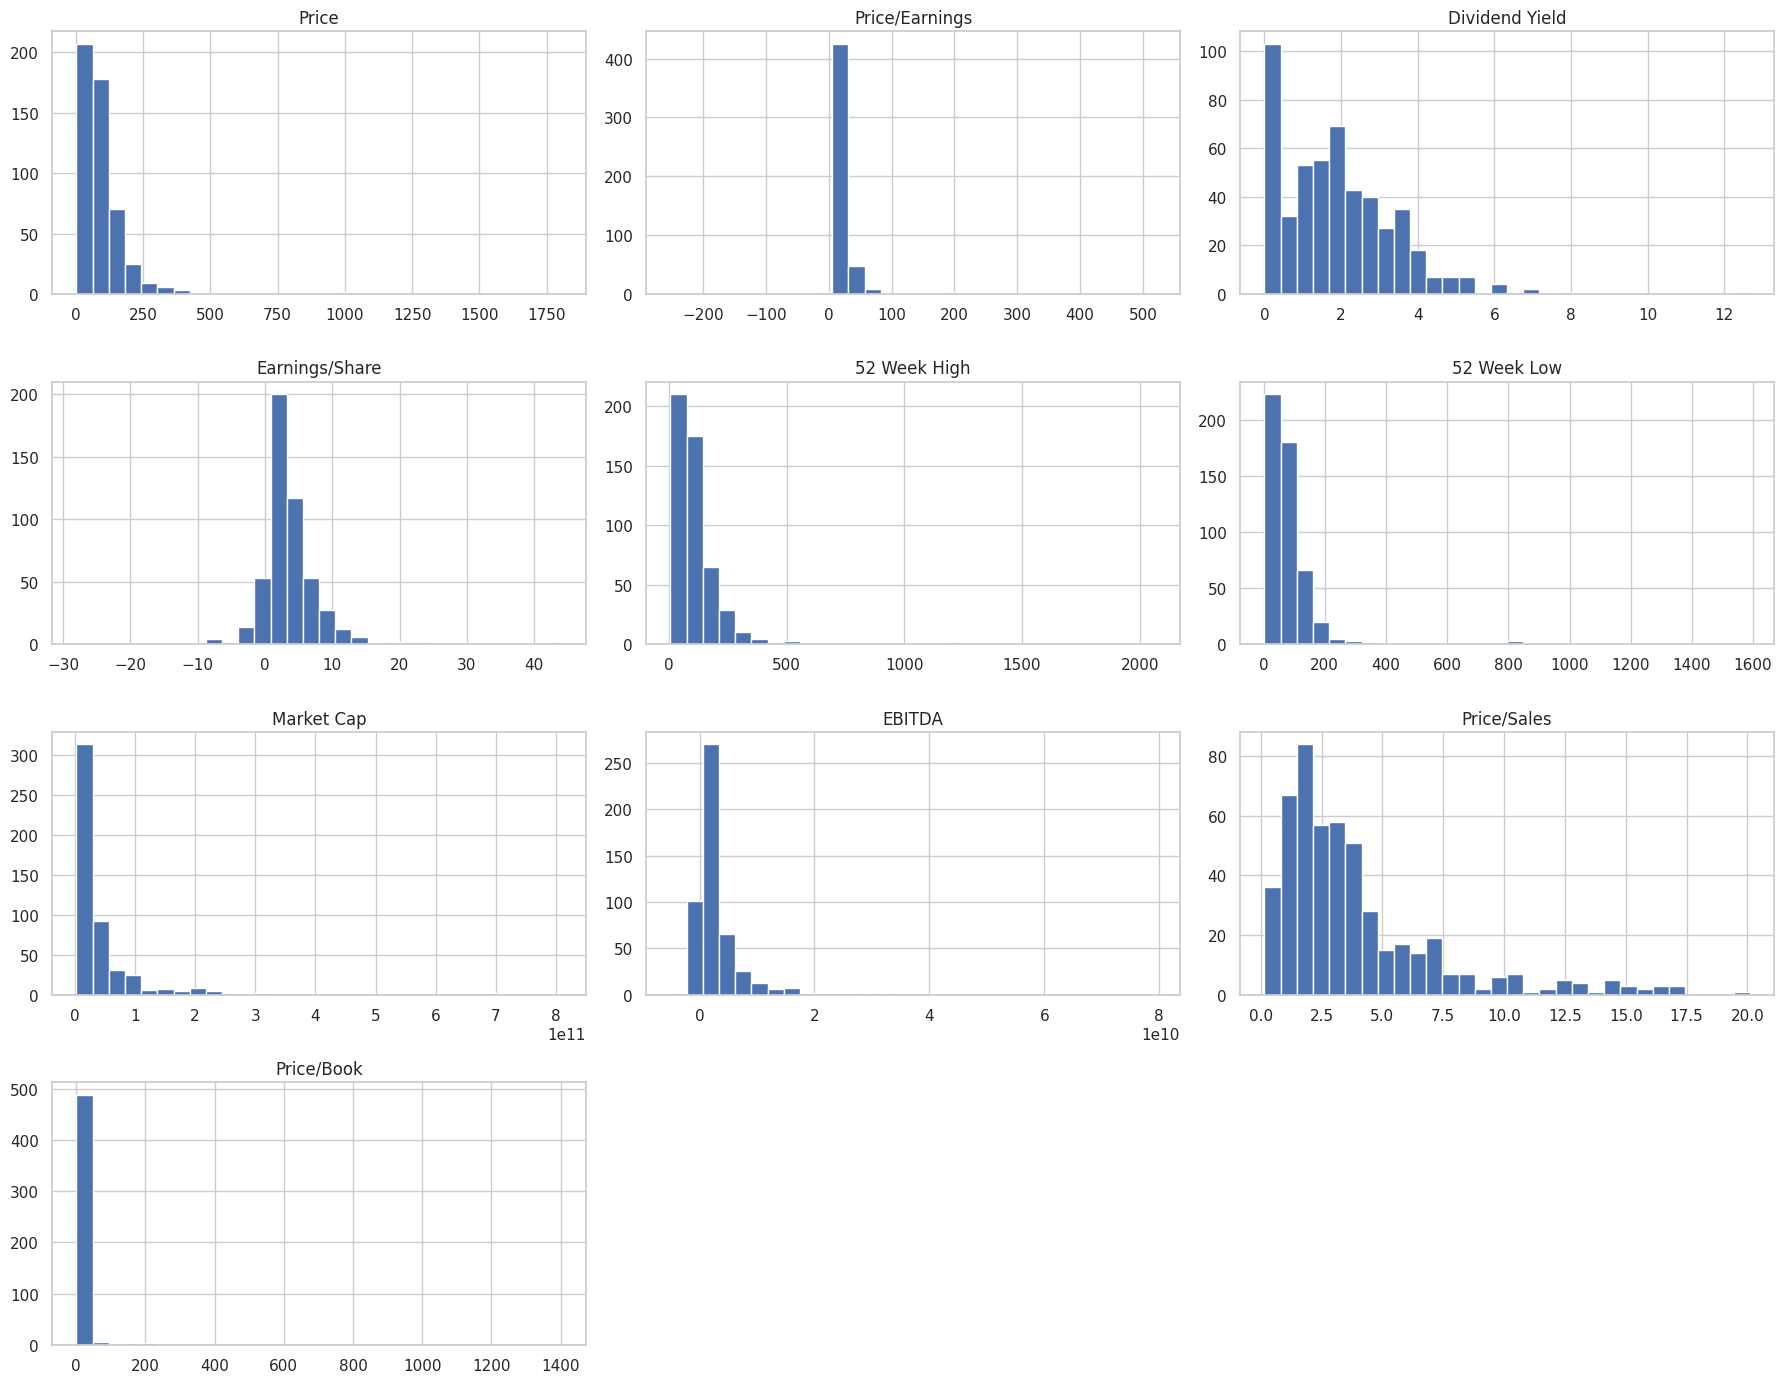

In [ ]:
import matplotlib.pyplot as plt

# Histogramas de todas las numéricas en una sola figura
df.hist(bins=30, figsize=(18, 14))
plt.tight_layout()
plt.show()

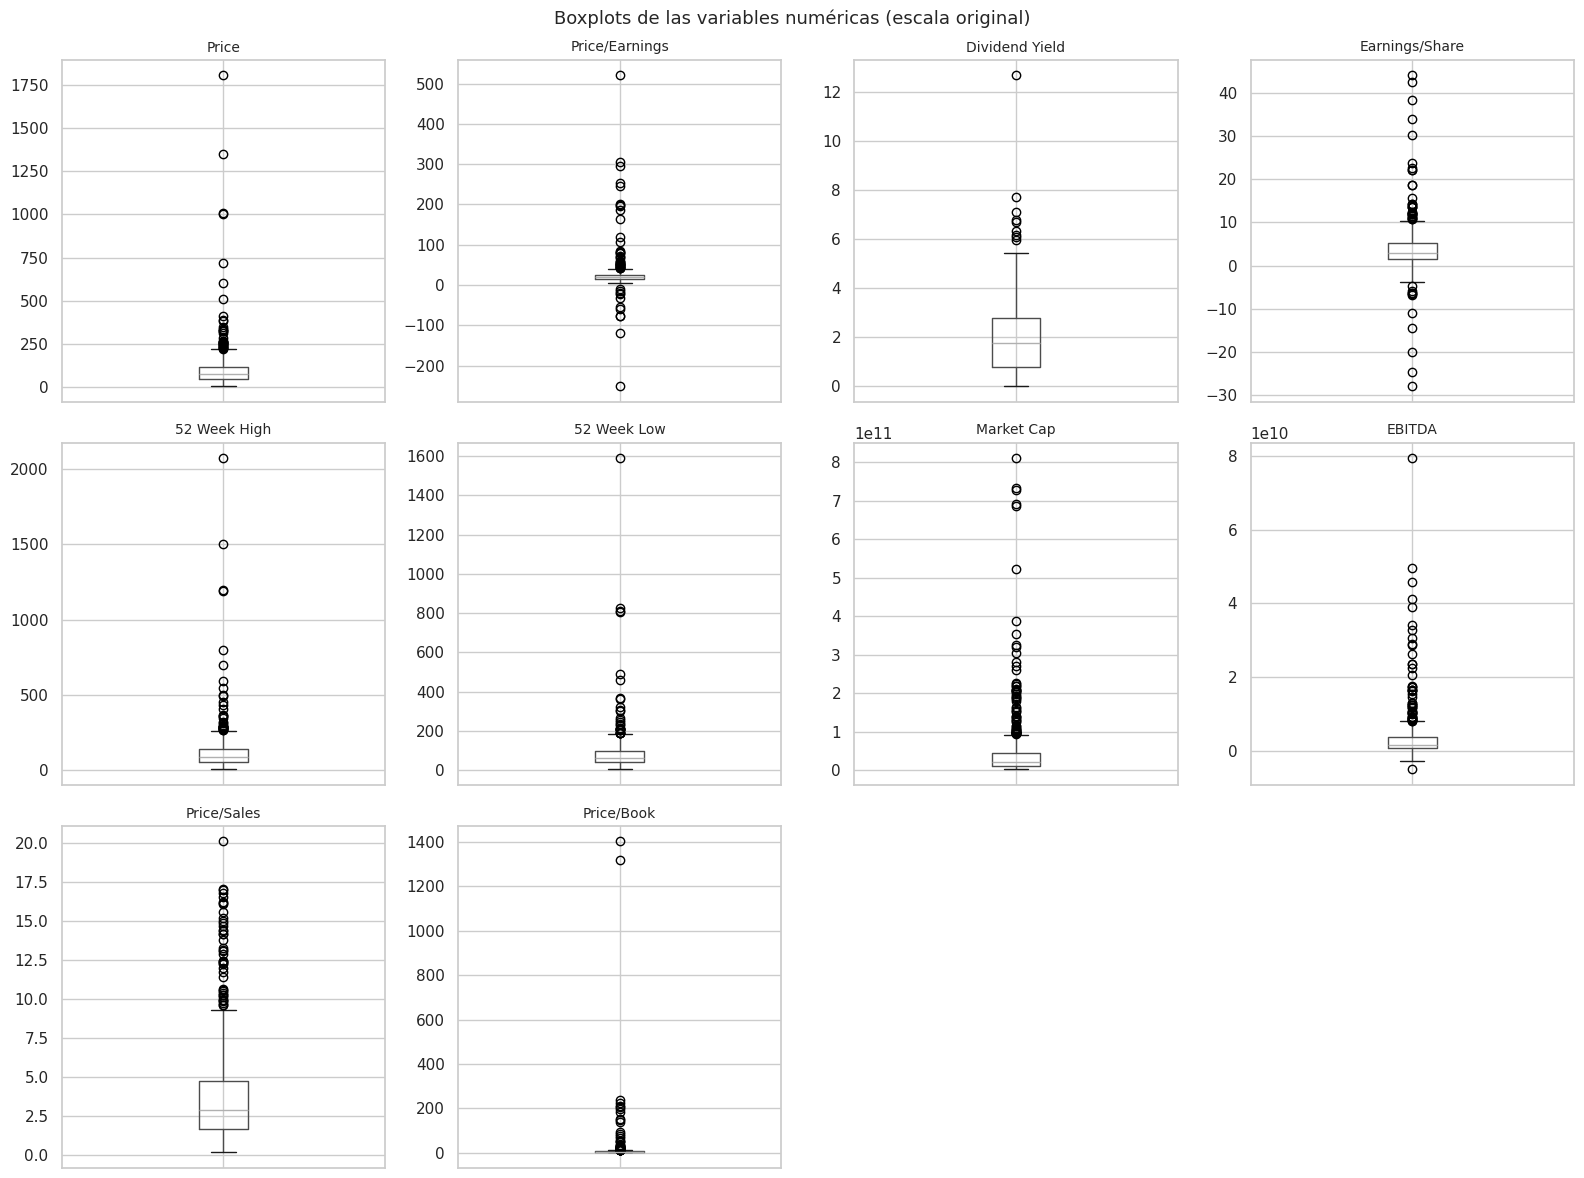

In [ ]:
import numpy as np

# Columnas numéricas del dataset
num_cols = df.select_dtypes(include="number").columns.tolist()

# Cuadrícula ajustada al número de variables
n_cols = 4
n_filas = int(np.ceil(len(num_cols) / n_cols))

fig, axes = plt.subplots(n_filas, n_cols, figsize=(16, 4 * n_filas))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    df.boxplot(column=col, ax=axes[i])
    axes[i].set_title(col, fontsize=10)
    axes[i].set_xticklabels([])          # quita el "col" repetido debajo de cada caja

# Ocultar los ejes sobrantes
for j in range(len(num_cols), len(axes)):
    axes[j].set_visible(False)

plt.suptitle("Boxplots de las variables numéricas (escala original)", fontsize=13)
plt.tight_layout()
plt.show()

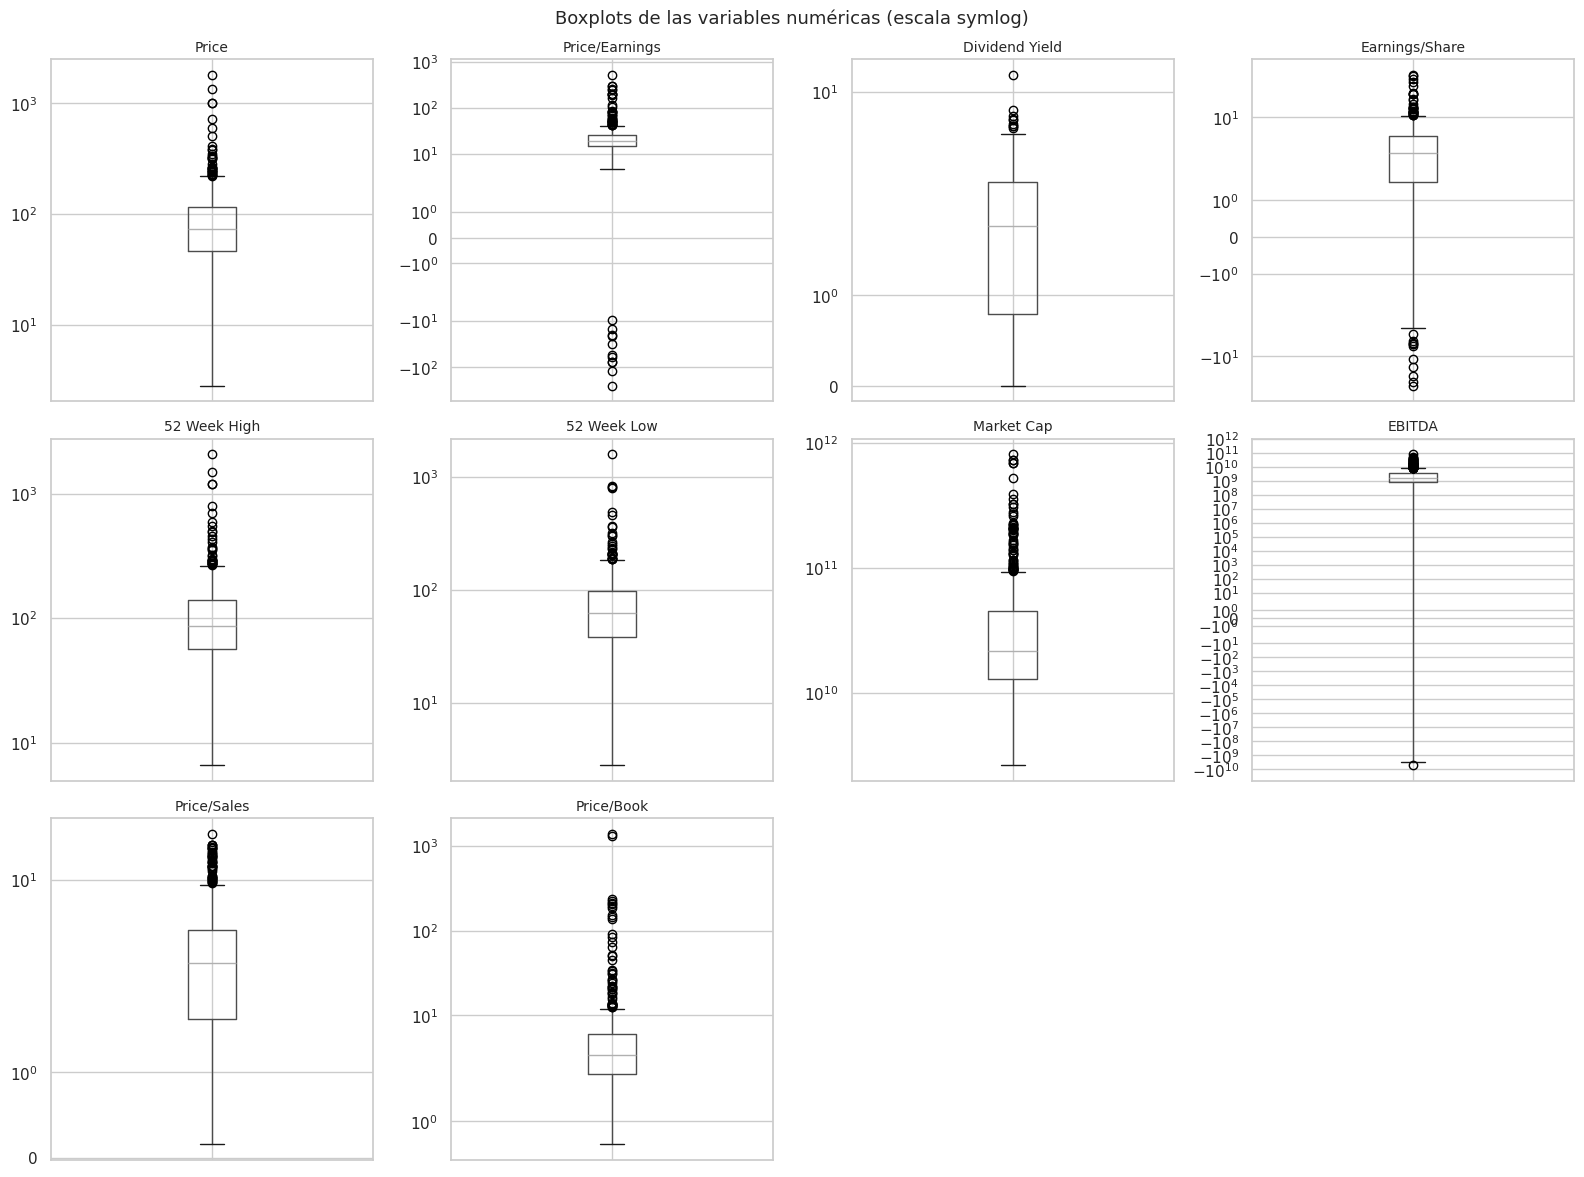

In [ ]:
# Los mismos boxplots en escala logarítmica simétrica (admite ceros y negativos)
fig, axes = plt.subplots(n_filas, n_cols, figsize=(16, 4 * n_filas))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    df.boxplot(column=col, ax=axes[i])
    axes[i].set_yscale("symlog")
    axes[i].set_title(col, fontsize=10)
    axes[i].set_xticklabels([])

for j in range(len(num_cols), len(axes)):
    axes[j].set_visible(False)

plt.suptitle("Boxplots de las variables numéricas (escala symlog)", fontsize=13)
plt.tight_layout()
plt.show()

**Análisis de las distribuciones.** Los histogramas y boxplots confirman lo observado en las estadísticas descriptivas:

- `Market Cap`, `EBITDA`, `Price/Earnings` y `Price/Book` tienen distribuciones fuertemente **sesgadas a la derecha** (asimetría de 5,2, 5,4, 5,2 y 13,9, respectivamente). La mayoría de las empresas se concentra en valores bajos, y unas pocas empresas muy grandes o con múltiplos extremos estiran la cola.
- En escala original, la caja de varios boxplots queda reducida a una línea porque los valores atípicos estiran el eje. En escala logarítmica, las distribuciones se vuelven legibles: esto anticipa que una **transformación logarítmica** será necesaria antes del agrupamiento.
- `Dividend Yield`, `Price/Sales` y `Earnings/Share` tienen una asimetría moderada (entre 1,3 y 1,9).
- `Price`, `52 Week High` y `52 Week Low` tienen formas prácticamente idénticas, lo que anticipa la redundancia que confirma la matriz de correlación.

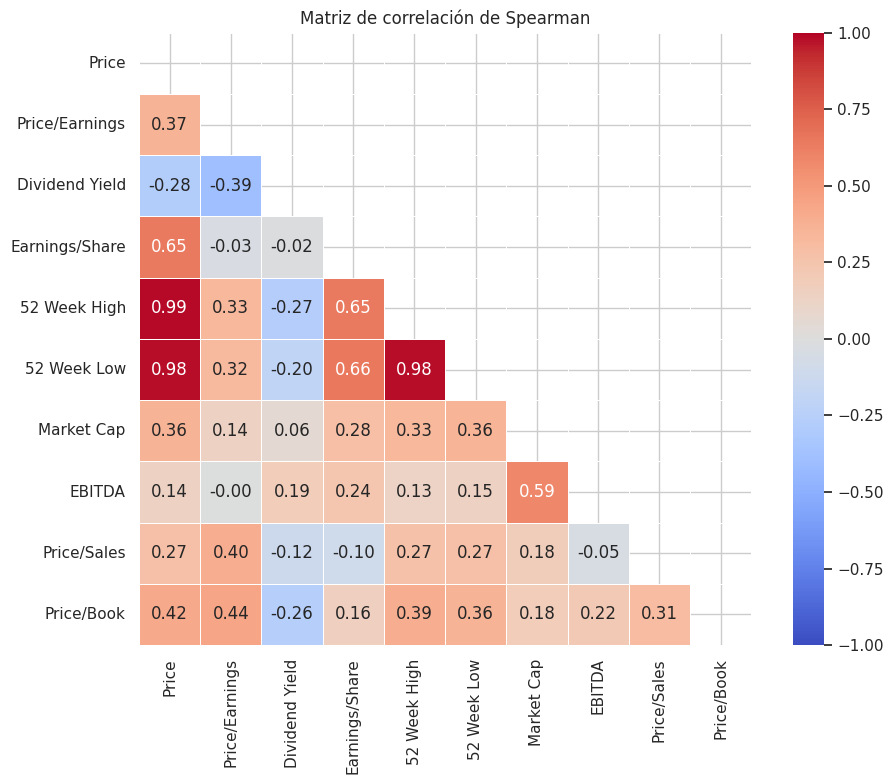

      Variable 1    Variable 2       rho
6   52 Week High         Price  0.990314
14   52 Week Low  52 Week High  0.978198
10   52 Week Low         Price  0.978032


In [ ]:
import seaborn as sns

num_cols = df.select_dtypes(include="number").columns.tolist()

# Spearman: robusta a outliers y captura relaciones monótonas no lineales
corr = df[num_cols].corr(method="spearman")

# Heatmap (solo triángulo inferior para no duplicar)
mask = np.triu(np.ones_like(corr, dtype=bool))
plt.figure(figsize=(10, 8))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1, center=0, square=True, linewidths=0.5)
plt.title("Matriz de correlación de Spearman")
plt.tight_layout()
plt.show()

# Pares con correlación alta (|ρ| > 0.8)
pares = (corr.where(np.tril(np.ones_like(corr, dtype=bool), k=-1))
             .stack()
             .rename("rho")
             .reset_index()
             .rename(columns={"level_0": "Variable 1", "level_1": "Variable 2"}))
print(pares[pares["rho"].abs() > 0.8].sort_values("rho", key=abs, ascending=False))

Price, 52 Week Low y 52 Week High presentan correlaciones de Spearman cercanas a 1, lo que haría que el nivel de precio tuviera triple peso en las distancias. Además, el precio por acción no es comparable entre empresas porque depende del número de acciones emitidas. Se reemplazan por dos medidas relativas: la posición del precio dentro del rango anual (momentum) y la amplitud del rango respecto al precio (volatilidad).

In [ ]:
# Variables derivadas del rango de 52 semanas
df["Posicion_52s"] = (df["Price"] - df["52 Week Low"]) / (df["52 Week High"] - df["52 Week Low"])
df["Amplitud_52s"] = (df["52 Week High"] - df["52 Week Low"]) / df["Price"]

# Validación: la posición debería estar entre 0 y 1
print("Filas con posición fuera de [0, 1]:",
      ((df["Posicion_52s"] < 0) | (df["Posicion_52s"] > 1)).sum())
print("¿Amplitud positiva en todas las filas?:", (df["Amplitud_52s"] > 0).all())

# Comprobar que las nuevas variables ya no son redundantes
num_cols = df.select_dtypes(include="number").columns.tolist()
print(df[num_cols].corr(method="spearman")[["Posicion_52s", "Amplitud_52s"]].round(2))

Filas con posición fuera de [0, 1]: 33
¿Amplitud positiva en todas las filas?: True
                Posicion_52s  Amplitud_52s
Price                   0.33          0.00
Price/Earnings          0.33          0.04
Dividend Yield         -0.39         -0.40
Earnings/Share          0.17         -0.09
52 Week High            0.26          0.06
52 Week Low             0.17         -0.12
Market Cap              0.21         -0.14
EBITDA                 -0.01         -0.10
Price/Sales             0.06         -0.05
Price/Book              0.32          0.12
Posicion_52s            1.00          0.28
Amplitud_52s            0.28          1.00


In [ ]:
# Empresas con precio por debajo del mínimo de 52 semanas
fuera = df[df["Posicion_52s"] < 0].copy()

# ¿Qué tan por debajo del mínimo está el precio?
fuera["Caida_vs_min_%"] = (fuera["Price"] / fuera["52 Week Low"] - 1) * 100

print(fuera["Caida_vs_min_%"].describe().round(2))
print(fuera["Caida_vs_min_%"].sort_values().round(1).values)

# ¿Coinciden con filas que tenían nulos imputados?
print("Empresas fuera de rango que tenían nulos:", fuera.index.isin(filas_con_nulos.index).sum())

# Eliminar las variables originales de nivel de precio
df = df.drop(columns=["Price", "52 Week Low", "52 Week High"])

count    33.00
mean     -1.31
std       0.64
min      -2.72
25%      -1.80
50%      -1.21
75%      -0.70
max      -0.23
Name: Caida_vs_min_%, dtype: float64
[-2.7 -2.2 -2.1 -2.  -2.  -1.9 -1.9 -1.9 -1.8 -1.8 -1.8 -1.7 -1.7 -1.6
 -1.5 -1.4 -1.2 -1.2 -1.2 -1.1 -1.1 -0.9 -0.9 -0.8 -0.7 -0.7 -0.7 -0.7
 -0.6 -0.5 -0.3 -0.2 -0.2]
Empresas fuera de rango que tenían nulos: 0


33 empresas (6,5%) presentaban un precio inferior a su mínimo de 52 semanas. Se descartó que fuera efecto de splits (la mayor diferencia es de −2,7%, lejos de proporciones como −50%) o de la imputación (ninguna de esas filas tenía valores nulos). Se atribuye a un desfase de pocos días entre la fecha del precio y la del cálculo del rango, por lo que su posición se acotó a 0, equivalente a ubicarlas en su mínimo anual

In [ ]:

df["Posicion_52s"] = df["Posicion_52s"].clip(0, 1)

In [ ]:
cols_num = df.select_dtypes(include="number").columns
perfil_sector = df.groupby("Sector")[cols_num].median()
perfil_sector["Market Cap"] = perfil_sector["Market Cap"] / 1e9
perfil_sector["EBITDA"] = perfil_sector["EBITDA"] / 1e9
perfil_sector = perfil_sector.rename(columns={"Market Cap": "Market Cap (mil mill. USD)",
                                              "EBITDA": "EBITDA (mil mill. USD)",
                                              "Dividend Yield": "Dividend Yield (%)"})
display(perfil_sector.round(2))

print("Empresas con EBITDA = 0 por sector:")
print(df.loc[df["EBITDA"] == 0, "Sector"].value_counts())

,Price/Earnings,Dividend Yield (%),Earnings/Share,Market Cap (mil mill. USD),EBITDA (mil mill. USD),Price/Sales,Price/Book,Posicion_52s,Amplitud_52s
Sector,,,,,,,,,
Consumer Discretionary,18.92,1.48,3.42,14.34,1.96,1.83,3.95,0.58,0.40
Consumer Staples,20.48,2.42,3.50,30.77,3.01,2.51,5.74,0.35,0.27
Energy,25.72,1.88,-1.14,22.01,2.41,3.03,2.24,0.32,0.42
Financials,16.30,1.93,3.49,26.62,0.00,2.88,1.60,0.57,0.30
Health Care,19.85,0.59,2.94,32.30,1.68,4.06,3.79,0.56,0.39
Industrials,21.60,1.47,4.80,19.36,1.64,2.16,4.27,0.56,0.34
Information Technology,25.16,1.09,2.16,26.94,1.67,4.73,5.84,0.60,0.37
Materials,23.26,1.58,4.14,16.96,2.15,2.53,3.66,0.49,0.31
Real Estate,16.55,3.71,1.77,14.39,1.26,10.25,2.32,0.00,0.28


Empresas con EBITDA = 0 por sector:
Sector
Financials                51
Health Care                4
Real Estate                2
Consumer Discretionary     1
Name: count, dtype: int64


La tabla muestra la mediana de cada variable por sector y permite anticipar qué sectores tienen una "huella financiera" distintiva:

- **Real Estate:** dividend yield alto (3,71%) y el P/S más alto (10,25). Es el perfil típico de los REIT, que por regulación deben distribuir la mayor parte de sus utilidades.
- **Utilities:** dividend yield alto (3,70%) y la menor amplitud de precio del índice (0,25), es decir, la menor volatilidad.
- **Financials:** EBITDA mediano igual a 0 (51 de las 58 empresas con EBITDA = 0 son financieras) y el P/B más bajo (1,60), típico de bancos y aseguradoras.
- **Energy:** EPS mediano negativo (−1,14). Muchas petroleras seguían registrando pérdidas tras la caída del precio del petróleo de 2014–2016.
- **Information Technology:** los múltiplos más altos (P/S de 4,73 y P/B de 5,84), propios de empresas *growth*.
- Real Estate y Utilities tienen además `Posicion_52s` mediana cercana a 0: al corte de los datos estaban cerca de sus mínimos anuales, lo que es coherente con el alza de las tasas de interés de inicios de 2018, que afecta a los sectores más sensibles a tasas.

En cambio, sectores como Industrials, Consumer Discretionary, Health Care o Materials tienen medianas muy parecidas entre sí. **Se espera que los algoritmos recuperen mejor los sectores con perfil distintivo y mezclen los demás.**

#Dataset final antes de la modelación

In [ ]:
df.head()

,Symbol,Name,Sector,Price/Earnings,Dividend Yield,Earnings/Share,Market Cap,EBITDA,Price/Sales,Price/Book,Posicion_52s,Amplitud_52s
0,MMM,3M Company,Industrials,24.31,2.332862,7.92,1.387211e+11,9.048000e+09,4.390271,11.34,0.562411,0.378124
1,AOS,A.O. Smith Corp,Industrials,27.76,1.147959,1.70,1.078342e+10,6.010000e+08,3.575483,6.35,0.581300,0.323124
2,ABT,Abbott Laboratories,Health Care,22.51,1.908982,0.26,1.021210e+11,5.744000e+09,3.740480,3.19,0.626792,0.396659
3,ABBV,AbbVie Inc.,Health Care,19.41,2.499560,3.29,1.813863e+11,1.031000e+10,6.291571,26.14,0.735906,0.606656
4,ACN,Accenture plc,Information Technology,25.47,1.714470,5.44,9.876586e+10,5.643228e+09,2.604117,10.62,0.746965,0.317454


Separacion de la etiqueta, con fines de comparación cuando se realice la agrupación

In [ ]:
ids = df[["Symbol", "Name"]].copy()
y = df["Sector"].copy()
X = df.drop(columns=["Sector", "Symbol", "Name"])

print("X:", X.shape, "| y:", y.shape)
print(y.value_counts())

X: (505, 9) | y: (505,)
Sector
Consumer Discretionary        84
Information Technology        70
Financials                    68
Industrials                   67
Health Care                   61
Consumer Staples              34
Real Estate                   33
Energy                        32
Utilities                     28
Materials                     25
Telecommunication Services     3
Name: count, dtype: int64


## Preprocesamiento para el agrupamiento

Los tres algoritmos de agrupamiento de este proyecto (K-means, jerárquico aglomerativo y DBSCAN) agrupan las empresas según qué tan **cercanas** están entre sí, medido con la distancia euclidiana. Por eso, antes de modelar es necesario preparar las variables para que esa distancia refleje diferencias financieras reales. La preparación se hace en tres pasos, y cada uno resuelve un problema distinto.

### Paso 1. Transformación logarítmica

**Problema: unos pocos valores extremos dominan cada variable.** El análisis exploratorio mostró que varias variables tienen distribuciones muy asimétricas. Por ejemplo, la mediana de Price/Book es 3,40, pero su máximo es 1.403; el P/E va de −251 a 520, y la capitalización bursátil va de 2.600 millones a más de 800.000 millones de dólares.

Esto es un problema porque K-means define el centro de cada grupo como el **promedio** de sus empresas, y el promedio es muy sensible a los extremos. Si en un grupo hay cuatro empresas con P/B entre 2 y 4 y una con P/B de 1.403, el promedio queda cerca de 283: un valor que no representa a ninguna de ellas. Además, como la distancia eleva las diferencias al cuadrado, las empresas atípicas quedan tan lejos de las demás que el algoritmo tiende a dedicarles grupos completos, en lugar de buscar estructura en la mayoría de los datos.

**Solución:** aplicar el logaritmo con signo,

$$x' = \text{sign}(x) \cdot \ln(1 + |x|)$$

El logaritmo **comprime los valores grandes sin cambiar el orden** de las empresas: la más cara sigue siendo la más cara, pero ya no está cientos de veces más lejos que las demás. Se usa la versión con signo porque P/E, EPS y EBITDA tienen valores negativos (empresas con pérdidas), y el logaritmo convencional no los admite.

**Justificación financiera:** además de la razón estadística, el logaritmo es la forma natural de comparar métricas financieras, porque hace que la distancia mida **diferencias relativas** y no absolutas. Pasar de un P/E de 10 a uno de 20 significa que el mercado paga el doble por cada dólar de utilidad; pasar de 100 a 110 es apenas un 10% más. Sin logaritmo, ambas diferencias valdrían lo mismo (10 unidades); con logaritmo, la primera pesa mucho más, como corresponde económicamente. Lo mismo ocurre con el tamaño: la diferencia entre una empresa de 10.000 y otra de 20.000 millones es significativa, mientras que entre una de 500.000 y otra de 510.000 millones no lo es.

Se transforman P/E, EPS, Market Cap, EBITDA, Price/Sales, Price/Book y Amplitud_52s. **Dividend Yield** y **Posicion_52s** no se transforman porque ya están en rangos acotados.

### Paso 2. Winsorización

**Problema: algunos extremos persisten después del logaritmo.** El logaritmo reduce mucho la asimetría, pero no la elimina en todos los casos. Por ejemplo, una empresa con EBITDA negativo de varios miles de millones queda, tras el logaritmo con signo, en el extremo opuesto de la escala respecto al resto.

**Solución:** recortar cada variable en sus percentiles 1 y 99. Los valores por debajo del percentil 1 se reemplazan por ese percentil, y los superiores al percentil 99 por el valor del percentil 99. **Ninguna empresa se elimina**; solo se limita la influencia que los casos más extremos pueden tener sobre los centros de los grupos.

### Paso 3. Estandarización

**Problema: las variables están en unidades distintas.** La capitalización bursátil y el EBITDA se miden en miles de millones de dólares, el dividend yield en porcentaje y Posicion_52s entre 0 y 1. La distancia euclidiana suma las diferencias de todas las variables sin considerar sus unidades, así que, sin estandarizar, las variables de tamaño dominarían por completo el cálculo: dos empresas de tamaño similar parecerían casi idénticas aunque una pagara 12 veces más dividendo que la otra.

**Solución:** estandarizar cada variable restando su media y dividiendo por su desviación estándar:

$$z = \frac{x - \bar{x}}{s}$$

Después de este paso, todas las variables tienen media 0 y desviación 1, y cada valor indica **cuántas desviaciones estándar se aleja la empresa del promedio**. Así, todas las variables contribuyen en igual medida a la distancia.

In [ ]:
import numpy as np
from sklearn.preprocessing import StandardScaler

def log_signo(s):
    """Logaritmo que conserva el signo: admite ceros y valores negativos."""
    return np.sign(s) * np.log1p(np.abs(s))

# 1. Logaritmo con signo en las variables con colas pesadas
cols_log = ["Price/Earnings", "Earnings/Share", "Market Cap", "EBITDA",
            "Price/Sales", "Price/Book", "Amplitud_52s"]

X_t = X.copy()
X_t[cols_log] = X_t[cols_log].apply(log_signo)

# 2. Winsorización en percentiles 1 y 99
X_t = X_t.clip(lower=X_t.quantile(0.01), upper=X_t.quantile(0.99), axis=1)

# Efecto sobre la asimetría
print(pd.DataFrame({"Asimetría original": X.skew(),
                    "Asimetría final": X_t.skew()}).round(2))

# 3. Estandarización
X_scaled = StandardScaler().fit_transform(X_t)
print("\nMatriz final:", X_scaled.shape, "| NaN:", np.isnan(X_scaled).sum())

                Asimetría original  Asimetría final
Price/Earnings                5.24            -4.33
Dividend Yield                1.30             0.68
Earnings/Share                1.89            -1.21
Market Cap                    5.24             0.77
EBITDA                        5.42            -2.58
Price/Sales                   1.90             0.47
Price/Book                   14.02             2.06
Posicion_52s                 -0.46            -0.47
Amplitud_52s                  2.70             1.51

Matriz final: (505, 9) | NaN: 0


#Agrupamiento con K-means


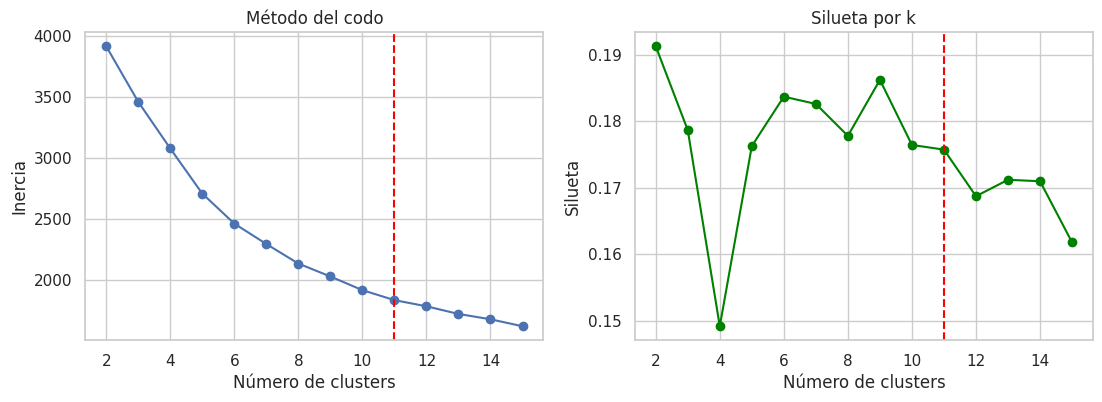

 k  Silueta
 2    0.191
 3    0.179
 4    0.149
 5    0.176
 6    0.184
 7    0.183
 8    0.178
 9    0.186
10    0.176
11    0.176
12    0.169
13    0.171
14    0.171
15    0.162


In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

inertia, siluetas = [], []
k_range = range(2, 16)

for k in k_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    lab = km.fit_predict(X_scaled)
    inertia.append(km.inertia_)
    siluetas.append(silhouette_score(X_scaled, lab))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(k_range, inertia, marker="o"); ax[0].set_title("Método del codo")
ax[0].set_xlabel("Número de clusters"); ax[0].set_ylabel("Inercia")
ax[1].plot(k_range, siluetas, marker="o", color="green"); ax[1].set_title("Silueta por k")
ax[1].set_xlabel("Número de clusters"); ax[1].set_ylabel("Silueta")
for a in ax: a.axvline(11, color="red", ls="--")
plt.show()

print(pd.DataFrame({"k": k_range, "Silueta": np.round(siluetas, 3)}).to_string(index=False))

La inercia disminuye rápidamente hasta k = 5 y, a partir de k = 6, la reducción por cada cluster adicional cae a menos de la mitad, lo que nos da a entender que hay un codo débil en torno a 5–6 grupos.

Además, la silueta confirma una estructura de agrupamiento débil, porque todos los valores se encuentran entre 0,15 y 0,19, por debajo del umbral de 0,25 que suele asociarse a grupos bien separados; por lo que se podría afirmar que actualmente los grupos se solapan un poco unos con otros.

El máximo se alcanza en k = 2, una partición demasiado gruesa para el objetivo del proyecto, y los siguientes mejores valores aparecen en k = 6 y k = 9. Para k = 11, el número de sectores GICS, la silueta es de 0,176, apenas inferior a esos valores, por lo que se utiliza k = 11 para comparar directamente con la clasificación sectorial, y k = 6 como alternativa sugerida por los datos.

### Modelo final (k = 11)

Como K-means es sensible a la inicialización de los centroides y puede quedar atrapado en un mínimo local, el modelo final se entrena con n_init=10: el algoritmo se ejecuta 10 veces con centroides iniciales distintos y conserva la solución de menor SSE. Así se obtiene la misma silueta de la exploración de k (0,176), lo que confirma que los resultados que siguen no dependen de una mala inicialización.

In [ ]:

# Modelo final
kmeans = KMeans(n_clusters=11, random_state=42, n_init=10)
kmeans.fit_predict(X_scaled)

labels_kmeans = kmeans.labels_

# Silhouette
sil_kmeans = silhouette_score(X_scaled, labels_kmeans)
print("Silhouette Score KMeans:", sil_kmeans)

Silhouette Score KMeans: 0.17572726422087306


### Composición de los clusters

In [ ]:
clasificacion = ids.copy()
clasificacion["Sector"] = y
clasificacion["Cluster"] = labels_kmeans

vars_clave = ["Price/Earnings", "Dividend Yield", "Market Cap", "EBITDA", "Price/Book", "Amplitud_52s"]

for c in sorted(clasificacion["Cluster"].unique()):
    grupo = clasificacion[clasificacion["Cluster"] == c]
    mediana = X.loc[grupo.index, vars_clave].median()

    print("=" * 90)
    print(f"CLUSTER {c}  |  {len(grupo)} empresas")
    print("-" * 90)
    print(f"P/E: {mediana['Price/Earnings']:.1f}  |  Div. Yield: {mediana['Dividend Yield']:.2f}  |  "
          f"Market Cap: {mediana['Market Cap']/1e9:.1f} mm USD  |  EBITDA: {mediana['EBITDA']/1e9:.2f} mm USD  |  "
          f"P/B: {mediana['Price/Book']:.1f}  |  Amplitud 52s: {mediana['Amplitud_52s']:.2f}")
    print("\nSectores:")
    for sector, n in grupo["Sector"].value_counts().items():
        print(f"   {sector:28s} {n:3d}  ({n/len(grupo):.0%})")
    print("\nEmpresas:")
    print(", ".join(grupo["Name"].sort_values()))
    print()

CLUSTER 0  |  66 empresas
------------------------------------------------------------------------------------------
P/E: 17.4  |  Div. Yield: 3.21  |  Market Cap: 17.6 mm USD  |  EBITDA: 2.15 mm USD  |  P/B: 2.3  |  Amplitud 52s: 0.26

Sectores:
   Utilities                     22  (33%)
   Consumer Staples              12  (18%)
   Consumer Discretionary        10  (15%)
   Information Technology         5  (8%)
   Industrials                    4  (6%)
   Materials                      3  (5%)
   Financials                     3  (5%)
   Energy                         3  (5%)
   Real Estate                    2  (3%)
   Health Care                    2  (3%)

Empresas:
AES Corp, Alliant Energy Corp, Ameren Corp, American Electric Power, American Water Works Company Inc, Archer-Daniels-Midland Co, Ball Corp, CA, Inc., CBS Corp., CMS Energy, CVS Health, Campbell Soup, CenterPoint Energy, Conagra Brands, Consolidated Edison, DTE Energy Co., Dominion Energy, Duke Energy, Edison Int'l, E

**Interpretación de K-means (k = 11).** Los clusters no reproducen los 11 sectores, pero cada uno tiene un perfil financiero reconocible:

| Cluster | Empresas | Perfil | Rasgo distintivo | Sectores dominantes |
|---|---|---|---|---|
| 8 | 27 | **REITs** | Dividend yield de 3,88 % | Real Estate 25 (93 %) |
| 2 | 59 | **Financiero** | EBITDA = 0 y P/B de 1,6 | Financials 49 (83 %) |
| 0 | 66 | **Defensivo** | Dividend yield de 3,21 % y baja volatilidad (0,26) | Utilities 22, Consumer Staples 12 |
| 10 | 70 | **Megacap** | Capitalización mediana de 99.500 millones de USD | Mixto (Apple, Microsoft, Alphabet, J&J, Exxon) |
| 1 | 30 | ***Growth* premium** | P/E de 39,2, sin dividendo y P/B de 13,4 | IT 13, Health Care 8 (Amazon, Nvidia, Netflix, Visa) |
| 6 | 86 | **Crecimiento moderado** | P/E de 25,7 y dividendo bajo (0,87 %) | IT 22, Industrials 18, Health Care 15 |
| 5 | 87 | **Núcleo cíclico** | Perfil cercano al promedio | Industrials 25, Consumer Discretionary 24 |
| 7 | 31 | **Energía con utilidades deprimidas** | P/E alto (26,3) con P/B bajo (2,8) | Energy 13 (petroleras) |
| 3 | 24 | **Volátiles y baratas** | La mayor amplitud de precio (0,85) y P/E de 11 | Consumer Discretionary 12 (retail) |
| 9 | 14 | **P/B extremo** | P/B de 167, por patrimonio reducido por recompras | Home Depot, Boeing, McDonald's |
| 4 | 11 | **Con pérdidas** | P/E negativo (−54,5) | Energy 6 |

K-means agrupa a las empresas más por **estilo de inversión** que por industria. Recupera con claridad **Real Estate** (el cluster 8 captura el 76 % del sector) y **Financials** (el cluster 2 captura el 72 %), y concentra el 79 % de **Utilities** en el cluster 0, aunque mezclado con otras empresas defensivas. Los demás sectores se reparten entre varios clusters, porque dentro de cada uno conviven empresas con perfiles financieros muy distintos. En el caso de Financials, el grupo se forma en buena medida por el EBITDA = 0 que la fuente asigna a bancos y aseguradoras.

#Clustering jerarquico aglomerativo


### Comparación de métodos de enlace

Se comparan tres métodos de enlace, que difieren en cómo definen la distancia entre dos grupos: **single** (los dos puntos más cercanos), **complete** (los dos más lejanos), **centroid** (la distancia entre centroides). Para cada uno se muestra el dendrograma truncado en las últimas 40 uniones

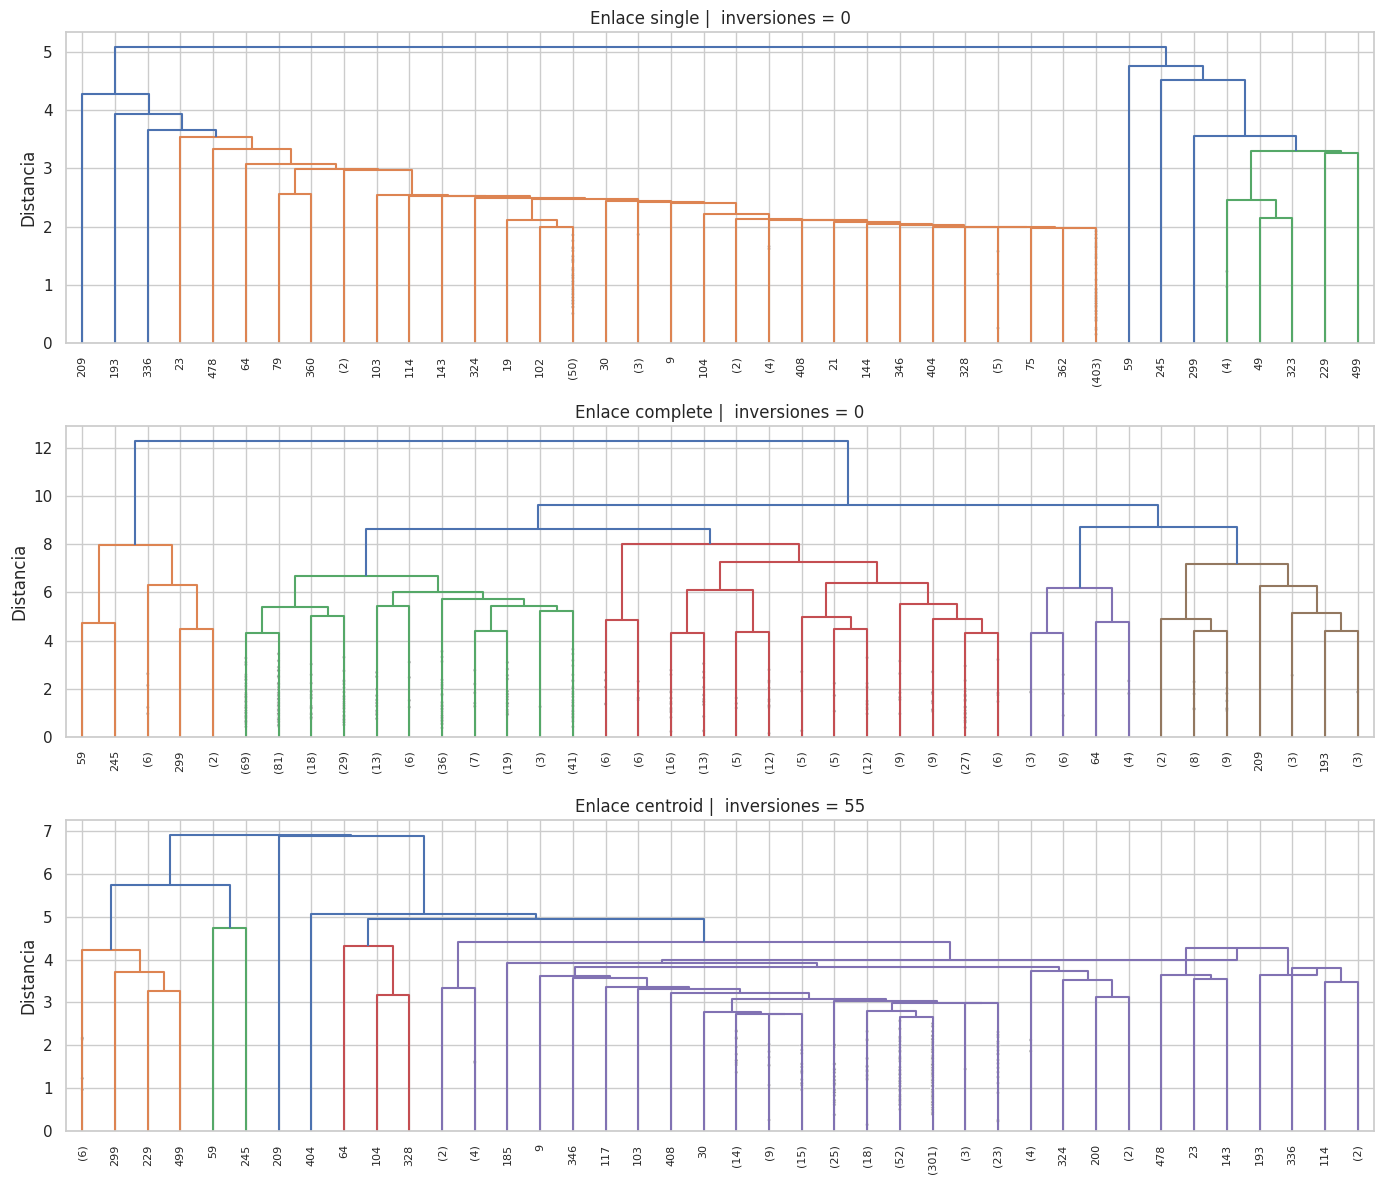

In [ ]:
metodos = ["single", "complete", "centroid"]
distancias_orig = pdist(X_scaled)
enlaces = {}

fig, axes = plt.subplots(len(metodos), 1, figsize=(14, 4 * len(metodos)))
for ax, metodo in zip(axes, metodos):
    Z = linkage(X_scaled, method=metodo)
    enlaces[metodo] = Z
    coph, _ = cophenet(Z, distancias_orig)
    inversiones = (np.diff(Z[:, 2]) < 0).sum()
    dendrogram(Z, truncate_mode="lastp", p=40, show_contracted=True, ax=ax,
               leaf_rotation=90, leaf_font_size=8)
    ax.set_title(f"Enlace {metodo} |  inversiones = {inversiones}")
    ax.set_ylabel("Distancia")
plt.tight_layout()
plt.show()

Los dendrogramas se leen de abajo hacia arriba: en el eje x están las empresas (entre paréntesis, cuántas hay en cada rama) y en el eje y la distancia a la que se fusionan.

El enlace single presenta el efecto cadena: un bloque de 403 empresas absorbe a las demás una a una, a distancias casi iguales. El enlace centroid también concentra la mayoría de las empresas en una sola rama y tiene 55 inversiones (fusiones que quedan por debajo de la anterior), así que su árbol no se puede cortar de forma coherente.

El enlace complete no tiene inversiones y forma ramas de tamaño más equilibrado. Como mide la distancia entre grupos por su par de empresas más lejano, solo une grupos que son compactos en su totalidad. Por eso es el único en el que trazar una línea de corte produce grupos interpretables.

### Distintos números de clusters por método

,Enlace,k,Silueta,Cluster mayor,% en cluster mayor,Clusters de 1-2 empresas
0,single,3,0.522,494,97.8,1
1,single,6,0.421,492,97.4,4
2,single,8,0.398,491,97.2,6
3,single,11,0.216,489,96.8,9
4,single,14,0.190,486,96.2,12
5,complete,3,0.262,453,89.7,0
6,complete,6,0.130,322,63.8,0
7,complete,8,0.110,322,63.8,1
8,complete,11,0.106,197,39.0,1
9,complete,14,0.105,197,39.0,2


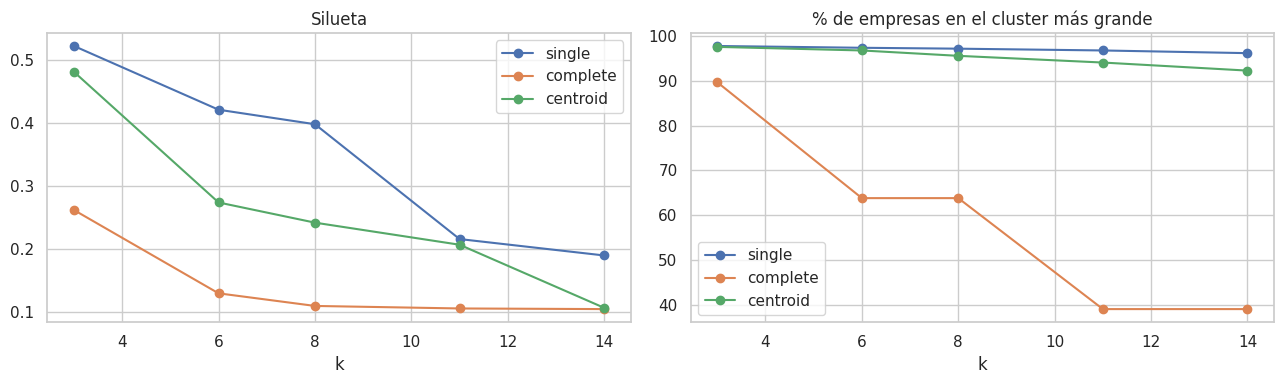

In [ ]:
valores_k = [3, 6, 8, 11, 14]
filas = []

for metodo, Z in enlaces.items():
    for k in valores_k:
        lab = fcluster(Z, t=k, criterion="maxclust")
        tam = np.sort(np.bincount(lab)[1:])[::-1]
        filas.append({
            "Enlace": metodo, "k": k,
            "Silueta": silhouette_score(X_scaled, lab),
            "Cluster mayor": tam[0],
            "% en cluster mayor": round(tam[0] / len(lab) * 100, 1),
            "Clusters de 1-2 empresas": (tam <= 2).sum(),
        })

resultados_jer = pd.DataFrame(filas).round(3)
display(resultados_jer)

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for metodo in metodos:
    sub = resultados_jer[resultados_jer["Enlace"] == metodo]
    ax[0].plot(sub["k"], sub["Silueta"], marker="o", label=metodo)
    ax[1].plot(sub["k"], sub["% en cluster mayor"], marker="o", label=metodo)
ax[0].set(title="Silueta", xlabel="k")
ax[1].set(title="% de empresas en el cluster más grande", xlabel="k")
for a in ax:
    a.legend()
plt.tight_layout()
plt.show()

Elección del método de enlace. La silueta no basta para elegir, porque favorece a los enlaces que producen las particiones menos útiles. Single (0,216 con k = 11) y centroid (0,207) tienen las siluetas más altas, pero concentran más del 94 % de las empresas en un solo grupo para todos los valores de k, y con k = 11 forman 9 y 6 grupos de una o dos empresas, respectivamente. Su silueta es alta porque separan unos pocos casos atípicos del resto, no porque encuentren grupos útiles.

Complete tiene la silueta más baja (0,106 con k = 11), pero es el único que reparte las empresas en grupos de tamaño útil: el grupo mayor baja del 89,7 % con k = 3 al 39,0 % con k = 11, y no presenta inversiones. Aun así, el grupo mayor se mantiene en 197 empresas entre k = 11 y k = 14, lo que indica un núcleo amplio de empresas con perfiles muy similares. Por eso se elige el enlace complete con k = 11 para comparar con los sectores GICS.

### Modelo final: enlace de complete con 11 clusters

Se entrena el modelo final con enlace complete y k = 11. Su silueta es de 0,106, la más baja de los tres algoritmos, coherente con los grupos solapados que también mostró K-means.

In [ ]:
#Modelo elegido
agg = AgglomerativeClustering(n_clusters=11, linkage = "complete")
labels_agg = agg.fit_predict(X_scaled)

sil_agg = silhouette_score(X_scaled, labels_agg)
print("Silhouette Score Agglomerative:", sil_agg)

Silhouette Score Agglomerative: 0.10614922409143779


### Composición de los clusters (aglomerativo, enlace complete, k = 11)

Se usa la misma lectura que en K-means: tamaño de cada grupo, mediana de las variables clave en escala original y distribución de sectores. Para no repetir código, se define una función que también se reutiliza en DBSCAN. En los grupos de más de 60 empresas solo se listan las 15 de mayor capitalización.

In [ ]:
def describir_clusters(labels, titulo, max_nombres=60):
    """Imprime, para cada cluster, su tamaño, el perfil financiero mediano y los sectores que contiene."""
    tabla = ids.copy()
    tabla["Sector"] = y
    tabla["Cluster"] = labels
    tabla["Market Cap"] = X["Market Cap"]
    vars_clave = ["Price/Earnings", "Dividend Yield", "Market Cap", "EBITDA", "Price/Book", "Amplitud_52s"]

    print(f"{titulo}\n")
    for c in sorted(tabla["Cluster"].unique()):
        grupo = tabla[tabla["Cluster"] == c]
        mediana = X.loc[grupo.index, vars_clave].median()
        nombre = "RUIDO (-1)" if c == -1 else f"CLUSTER {c}"
        print("=" * 90)
        print(f"{nombre}  |  {len(grupo)} empresas")
        print("-" * 90)
        print(f"P/E: {mediana['Price/Earnings']:.1f}  |  Div. Yield: {mediana['Dividend Yield']:.2f}  |  "
              f"Market Cap: {mediana['Market Cap']/1e9:.1f} mm USD  |  EBITDA: {mediana['EBITDA']/1e9:.2f} mm USD  |  "
              f"P/B: {mediana['Price/Book']:.1f}  |  Amplitud 52s: {mediana['Amplitud_52s']:.2f}")
        print(f"EPS negativo: {(X.loc[grupo.index, 'Earnings/Share'] < 0).mean():.0%}  |  "
              f"EBITDA = 0: {(X.loc[grupo.index, 'EBITDA'] == 0).mean():.0%}")
        print("\nSectores:")
        for sector, n in grupo["Sector"].value_counts().items():
            print(f"   {sector:28s} {n:3d}  ({n/len(grupo):.0%})")
        if len(grupo) <= max_nombres:
            print("\nEmpresas:")
            print(", ".join(grupo["Name"].sort_values()))
        else:
            print("\nLas 15 empresas de mayor capitalización:")
            print(", ".join(grupo.nlargest(15, "Market Cap")["Name"]))
        print()

describir_clusters(labels_agg, "CLUSTERING AGLOMERATIVO (enlace complete, k = 11)")

CLUSTERING AGLOMERATIVO (enlace complete, k = 11)

CLUSTER 0  |  9 empresas
------------------------------------------------------------------------------------------
P/E: -32.0  |  Div. Yield: 2.10  |  Market Cap: 12.9 mm USD  |  EBITDA: 0.48 mm USD  |  P/B: 2.2  |  Amplitud 52s: 0.51
EPS negativo: 100%  |  EBITDA = 0: 11%

Sectores:
   Energy                         6  (67%)
   Materials                      1  (11%)
   Consumer Discretionary         1  (11%)
   Financials                     1  (11%)

Empresas:
Anadarko Petroleum Corp, Apache Corporation, CF Industries Holdings Inc, Helmerich & Payne, Hess Corporation, Marathon Oil Corp., Mattel Inc., National Oilwell Varco Inc., XL Capital

CLUSTER 1  |  8 empresas
------------------------------------------------------------------------------------------
P/E: 16.6  |  Div. Yield: 1.91  |  Market Cap: 31.2 mm USD  |  EBITDA: 0.00 mm USD  |  P/B: 1.2  |  Amplitud 52s: 0.36
EPS negativo: 88%  |  EBITDA = 0: 62%

Sectores:
   Financial

In [ ]:
# Perfil mediano de cada cluster en escala original (todas las variables)
perfil_agg = X.groupby(labels_agg).median()
perfil_agg["Market Cap"] /= 1e9
perfil_agg["EBITDA"] /= 1e9
perfil_agg.insert(0, "Empresas", pd.Series(labels_agg).value_counts().sort_index())
perfil_agg.index.name = "Cluster"
perfil_agg = perfil_agg.rename(columns={"Market Cap": "Market Cap (mm USD)", "EBITDA": "EBITDA (mm USD)"})
display(perfil_agg.round(2))

,Empresas,Price/Earnings,Dividend Yield,Earnings/Share,Market Cap (mm USD),EBITDA (mm USD),Price/Sales,Price/Book,Posicion_52s,Amplitud_52s
Cluster,,,,,,,,,,
0,9,-32.00,2.10,-3.06,12.94,0.48,3.65,2.22,0.54,0.51
1,8,16.60,1.91,-2.71,31.19,0.00,1.44,1.17,0.13,0.36
2,125,16.45,3.39,2.57,18.89,2.20,2.62,2.14,0.14,0.28
3,14,9.58,2.49,0.98,6.00,1.21,1.37,1.38,0.11,0.95
4,51,32.57,0.00,1.81,16.92,0.93,6.98,8.81,0.66,0.42
5,12,23.10,2.38,6.38,79.03,5.59,2.18,148.86,0.54,0.37
6,2,-98.48,0.00,-1.03,21.28,-0.23,16.77,117.19,0.23,0.65
7,46,19.78,0.24,1.60,13.20,1.46,2.07,2.66,0.46,0.52
8,19,16.34,1.64,4.50,56.67,0.00,2.10,1.58,0.48,0.32


**Interpretación del clustering aglomerativo (enlace complete, k = 11).** El modelo produce una partición muy desigual: dos grupos grandes concentran 322 de las 505 empresas (64%) y el resto se reparte en grupos pequeños que aíslan perfiles extremos.

| Cluster | Empresas | Perfil financiero | Sectores dominantes |
|---|---|---|---|
| 9 | 197 | Núcleo "promedio": medianas casi iguales a las de toda la muestra (P/E 20,6; dividend yield 1,62%; P/B 3,8) | Industrials 45, Financials 37, Consumer Discretionary 34, Health Care 23 |
| 2 | 125 | **Defensivo / de rentas:** el dividend yield más alto (3,39%), la menor amplitud de precio (0,28) y precio cerca del mínimo anual (posición 0,14) | Real Estate 24, Utilities 23, Consumer Discretionary 17, Consumer Staples 12, Energy 12 |
| 4 | 51 | **Growth:** no paga dividendo (mediana 0%), P/E de 32,6, P/S de 7,0 y P/B de 8,8 | Information Technology 22, Health Care 14 |
| 7 | 46 | Dividendo casi nulo (0,24%) y volatilidad alta (amplitud 0,52); 37% con EPS negativo | Consumer Discretionary 17, Energy 8 |
| 10 | 22 | **Megacap:** capitalización mediana de 207 mil millones y EBITDA de 15,8 mil millones | Information Technology 12, Health Care 4 (Apple, Alphabet, Microsoft, Amazon, Facebook, Johnson & Johnson…) |
| 8 | 19 | EBITDA = 0 en el 89% de las empresas | Financials 14 y 5 aseguradoras de salud |
| 3 | 14 | **Muy volátiles y baratas:** amplitud de 0,95 (la más alta) y P/E de 9,6 | Energy 4, Consumer Discretionary 4 |
| 5 | 12 | P/B extremo (mediana de 149), propio de empresas con patrimonio contable muy reducido por recompras de acciones | Home Depot, Boeing, Lockheed Martin, Colgate-Palmolive… |
| 0 | 9 | Todas con EPS negativo y P/E negativo | Energy 6 (petroleras con pérdidas) |
| 1 | 8 | Pérdidas contables (88% con EPS negativo) en empresas grandes | AIG, Citigroup, General Electric, MetLife… |
| 6 | 2 | P/E negativo, P/S de 16,8 y P/B de 117 | Autodesk e Incyte |



Al igual que K-means, el modelo agrupa por estilo de inversión (defensivo, growth, megacap, con pérdidas, volátil) y no por industria, pero recupera menos sectores. Real Estate y Utilities quedan juntos en el cluster 2, porque comparten dividendo alto y baja volatilidad, y Financials se divide: solo 14 de las 68 financieras forman el grupo de EBITDA = 0 (cluster 8) y 37 quedan dentro del núcleo de 197 empresas. Esto refleja cómo funciona el enlace complete: una empresa atípica dentro de un grupo impide que se una a otro, así que se forman grupos pequeños alrededor de los casos extremos y la mayoría queda en pocos grupos grandes.

#DBSCAN

DBSCAN no recibe el número de clusters: este resulta de dos parámetros, `eps` (el radio del vecindario) y `min_samples` (el número mínimo de vecinas para considerar una zona densa). Las empresas que no pertenecen a ninguna zona densa se marcan como **ruido** (−1). Para elegir `eps` se usa el gráfico de k-distancias, y se evalúan varias combinaciones de parámetros. La silueta se calcula **sin el ruido**, ya que el ruido no es un grupo.

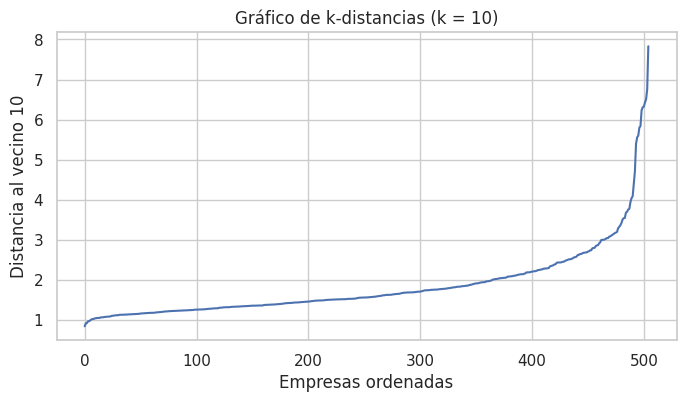

,eps,min_samples,Clusters,% ruido,Silueta sin ruido
0,1.0,5,5,76.2,0.177
1,1.0,10,3,92.7,0.452
2,1.0,18,0,100.0,NaN
3,1.5,5,3,25.1,0.162
4,1.5,10,2,32.5,0.245
5,1.5,18,2,40.8,0.269
6,2.0,5,2,10.5,0.198
7,2.0,10,2,14.1,0.210
8,2.0,18,2,17.0,0.218
9,2.5,5,1,5.1,NaN


In [ ]:
from sklearn.neighbors import NearestNeighbors

min_samples = 10
vecinos = NearestNeighbors(n_neighbors=min_samples).fit(X_scaled)
distancias = np.sort(vecinos.kneighbors(X_scaled)[0][:, -1])

plt.figure(figsize=(8, 4))
plt.plot(distancias)
plt.title(f"Gráfico de k-distancias (k = {min_samples})")
plt.xlabel("Empresas ordenadas")
plt.ylabel(f"Distancia al vecino {min_samples}")
plt.show()

filas = []
for eps in [1.0, 1.5, 2.0, 2.5, 3.0]:
    for ms in [5, 10, 18]:
        lab = DBSCAN(eps=eps, min_samples=ms).fit_predict(X_scaled)
        n_cl = len(set(lab)) - (1 if -1 in lab else 0)
        ruido = (lab == -1).mean()
        sil = silhouette_score(X_scaled[lab != -1], lab[lab != -1]) if n_cl > 1 else np.nan
        filas.append([eps, ms, n_cl, round(ruido * 100, 1), round(sil, 3)])

display(pd.DataFrame(filas, columns=["eps", "min_samples", "Clusters", "% ruido", "Silueta sin ruido"]))


Selección de parámetros:

DBSCAN necesita dos valores: eps, que es el radio alrededor de cada empresa, y min_samples, el número mínimo de empresas que debe haber dentro de ese radio para formar un grupo. Las empresas que no alcanzan a quedar dentro de ningún grupo se marcan como ruido.

Para escoger eps se usó el gráfico de k-distancias, que muestra qué tan lejos está cada empresa de su décima vecina más cercana. Casi todas las empresas tienen a sus 10 vecinas a una distancia de entre 1 y 2,5, pero al final de la curva unas pocas empresas quedan muy lejos de las demás: son las empresas atípicas. Por eso el valor razonable de eps está entre 2 y 3.

La tabla muestra qué pasa al cambiar eps:

Radio pequeño (eps = 1 o 1,5): las exigencias son altas y muchas empresas quedan como ruido, entre el 25 % y el 100 %.
Radio grande (eps = 2,5 o 3): casi todas las empresas quedan conectadas en un solo grupo.
eps = 2: es el punto intermedio. Siempre salen 2 grupos y solo entre el 10 % y el 17 % de las empresas queda como ruido.

En ningún caso DBSCAN encuentra muchos grupos sin dejar a la mayoría como ruido. Esto significa que las empresas no forman varias zonas densas separadas, sino una sola nube continua.

Para cumplir el punto 5.1, se exploran también valores menores de
`min_samples`, que son los que permiten obtener más clusters:

In [ ]:
filas = []
for eps in [0.6, 0.8, 1.0, 1.2, 1.5, 2.0]:
    for ms in [3, 4, 5]:
        lab = DBSCAN(eps=eps, min_samples=ms).fit_predict(X_scaled)
        n_cl = len(set(lab)) - (1 if -1 in lab else 0)
        filas.append([eps, ms, n_cl, round((lab == -1).mean() * 100, 1)])

dbscan_k = pd.DataFrame(filas, columns=["eps", "min_samples", "Clusters", "% ruido"])
display(dbscan_k.sort_values("Clusters", ascending=False))

,eps,min_samples,Clusters,% ruido
6,1.0,3,16,61.2
3,0.8,3,12,88.1
7,1.0,4,9,69.7
9,1.2,3,8,40.0
12,1.5,3,7,20.2
8,1.0,5,5,76.2
10,1.2,4,5,44.4
15,2.0,3,5,6.1
4,0.8,4,4,94.5
11,1.2,5,4,47.9


Al bajar min_samples a 3 o 4, DBSCAN exige muy pocas vecinas para formar un grupo, así que aparecen más clusters, pero muy pequeños. Solo es posible acercarse a 11 clusters o superarlos con eps ≤ 1,0: por ejemplo, 9 clusters con 69,7 % de ruido, 12 con 88,1 % o 16 con 61,2 %. Es decir, para obtener tantos grupos, DBSCAN tiene que descartar a la mayoría de las empresas como ruido.

Con un radio mayor, el ruido baja, pero los grupos se unen: con eps = 2,0 y min_samples = 3 salen 5 clusters con solo 6,1 % de ruido, aunque con un mínimo de 3 empresas por grupo es una partición formada por grupos diminutos alrededor de una masa principal. Esto confirma que en los datos no existen 11 zonas densas diferenciadas.

Solo es posible acercarse a 11 clusters o superarlos con eps ≤ 1,0 y min_samples de 3 o 4: por ejemplo, 9 clusters con 69,7% de ruido, 12 clusters con 88,1% de ruido o 16 clusters con 61,2% de ruido. Es decir, para obtener tantos grupos, DBSCAN debe descartar a la mayoría de las empresas. Esto indica que en los datos no existen 11 zonas densas diferenciadas.

In [ ]:
dbscan = DBSCAN(eps=2.0, min_samples=10)
labels_db = dbscan.fit_predict(X_scaled)

n_clusters_db = len(set(labels_db)) - (1 if -1 in labels_db else 0)
print("Clusters encontrados:", n_clusters_db)
print("Empresas marcadas como ruido:", (labels_db == -1).sum(), f"({(labels_db == -1).mean():.1%})")

# Silueta SIN el ruido
mask = labels_db != -1
if n_clusters_db > 1:
    sil_db = silhouette_score(X_scaled[mask], labels_db[mask])
    print("Silhouette Score DBSCAN (sin ruido):", round(sil_db, 3))
else:
    sil_db = np.nan
    print("Silueta no calculable: hay un solo cluster")

Clusters encontrados: 2
Empresas marcadas como ruido: 71 (14.1%)
Silhouette Score DBSCAN (sin ruido): 0.21


In [ ]:
for eps, ms in [(2.0, 10), (3.0, 5)]:
    lab = DBSCAN(eps=eps, min_samples=ms).fit_predict(X_scaled)
    tam = pd.Series(lab).value_counts().sort_index()
    print(f"eps = {eps}, min_samples = {ms}:")
    print(tam.rename({-1: "Ruido"}).to_string(), "\n")

eps = 2.0, min_samples = 10:
Ruido     71
0        386
1         48 

eps = 3.0, min_samples = 5:
Ruido     13
0        486
1          6 



Se evaluaron combinaciones de eps entre 1,0 y 3,0 y de min_samples entre 5 y 18. Con eps ≤ 1,5, más del 25% de las empresas se clasifica como ruido, por lo que el modelo no describe la mayor parte del dataset. Con eps ≥ 2,5, casi todas las empresas quedan conectadas en un único grupo. La zona estable se encuentra en eps = 2,0, donde las tres combinaciones de min_samples producen 2 clusters, entre 10,5% y 17% de ruido y siluetas de 0,20 a 0,22. Se elige **eps = 2,0 y min_samples = 10**.

La combinación eps = 3,0 y min_samples = 5 obtuvo la silueta más alta (0,52), pero es una partición degenerada: el 96,2% de las empresas (486) queda en un único grupo y el segundo grupo tiene solo 6 empresas. Su silueta elevada refleja la separación de ese pequeño grupo, no una estructura útil.

### Composición de los grupos y del ruido

In [ ]:
describir_clusters(labels_db, "DBSCAN (eps = 2,0, min_samples = 10)")

DBSCAN (eps = 2,0, min_samples = 10)

RUIDO (-1)  |  71 empresas
------------------------------------------------------------------------------------------
P/E: 16.2  |  Div. Yield: 1.80  |  Market Cap: 14.1 mm USD  |  EBITDA: 0.96 mm USD  |  P/B: 2.6  |  Amplitud 52s: 0.51
EPS negativo: 44%  |  EBITDA = 0: 14%

Sectores:
   Energy                        17  (24%)
   Consumer Discretionary        15  (21%)
   Financials                     8  (11%)
   Health Care                    8  (11%)
   Utilities                      6  (8%)
   Industrials                    4  (6%)
   Information Technology         4  (6%)
   Real Estate                    4  (6%)
   Consumer Staples               3  (4%)
   Telecommunication Services     1  (1%)
   Materials                      1  (1%)

Las 15 empresas de mayor capitalización:
Amazon.com Inc, Facebook, Inc., Home Depot, Boeing Company, Citigroup Inc., Philip Morris International, General Electric, McDonald's Corp., United Parcel Service, Char

In [ ]:
# ¿Qué distingue al ruido? Perfil mediano del ruido frente a los dos clusters y a la muestra completa
grupos_db = pd.Series(np.where(labels_db == -1, "Ruido", "Cluster " + pd.Series(labels_db).astype(str)),
                      index=X.index)
perfil_db = X.groupby(grupos_db).median()
perfil_db.loc["Muestra completa"] = X.median()
perfil_db["Market Cap"] /= 1e9
perfil_db["EBITDA"] /= 1e9
perfil_db["% EPS negativo"] = (X["Earnings/Share"] < 0).groupby(grupos_db).mean().reindex(perfil_db.index) * 100
perfil_db.loc["Muestra completa", "% EPS negativo"] = (X["Earnings/Share"] < 0).mean() * 100
perfil_db = perfil_db.rename(columns={"Market Cap": "Market Cap (mm USD)", "EBITDA": "EBITDA (mm USD)"})
display(perfil_db.round(2))

# Proporción de cada sector que DBSCAN marcó como ruido
ruido_sector = (pd.crosstab(y, labels_db == -1, normalize="index")[True] * 100).sort_values(ascending=False)
print("Porcentaje de cada sector clasificado como ruido:")
print(ruido_sector.round(1).to_string())

,Price/Earnings,Dividend Yield,Earnings/Share,Market Cap (mm USD),EBITDA (mm USD),Price/Sales,Price/Book,Posicion_52s,Amplitud_52s,% EPS negativo
Cluster 0,20.32,1.72,2.95,21.64,1.92,3.05,3.81,0.52,0.34,5.18
Cluster 1,16.30,1.82,4.12,29.98,0.00,2.56,1.58,0.60,0.31,0.00
Ruido,16.22,1.80,0.63,14.11,0.96,2.19,2.61,0.26,0.51,43.66
Muestra completa,19.45,1.77,2.89,21.40,1.61,2.90,3.40,0.51,0.35,10.10


Porcentaje de cada sector clasificado como ruido:
Sector
Energy                        53.1
Telecommunication Services    33.3
Utilities                     21.4
Consumer Discretionary        17.9
Health Care                   13.1
Real Estate                   12.1
Financials                    11.8
Consumer Staples               8.8
Industrials                    6.0
Information Technology         5.7
Materials                      4.0


**Interpretación de DBSCAN.**

El modelo encuentra solo dos zonas densas y un grupo de empresas atípicas:

- **Cluster 0 (386 empresas): todo lo demás.** Sus medianas son casi iguales a las de la muestra completa y contiene todos los sectores. Para DBSCAN, las empresas no financieras forman una sola nube continua que no se puede dividir.
- **Cluster 1 (48 empresas): el bloque financiero.** El 92 % son Financials, y lo que lo separa es que el 100 % tiene EBITDA = 0, un valor que la fuente asigna a bancos y aseguradoras.
- **Ruido (71 empresas): las empresas atípicas.** El 44 % tiene pérdidas (frente al 10 % de la muestra), son más volátiles y su precio está cerca del mínimo anual. El 53 % de Energy queda como ruido, por las pérdidas que muchas petroleras arrastraban tras la caída del petróleo de 2014–2016.

El aporte más útil de DBSCAN no son los grupos sino el ruido, que funciona como **detector de empresas atípicas**.

#Comparación de los modelos frente a los sectores GICS

En esta sección se usa por primera vez la variable `Sector`, solo como referencia externa, para responder: **¿cuál de los tres modelos se acerca más a recrear los 11 sectores tal como los presenta la base de datos?**

La silueta no sirve para responder esta pregunta, porque mide qué tan separados están los grupos entre sí, no si se parecen a los sectores. Por eso se usan métricas **externas**, que comparan la partición de cada modelo con la clasificación real:

| Métrica | Qué mide | Interpretación |
|---|---|---|
| **ARI** (*Adjusted Rand Index*) | Para cada par de empresas, si ambas particiones coinciden en ponerlas juntas o separadas. Está corregido por azar | 0 = parecido equivalente al azar; 1 = sectores reproducidos exactamente. **Métrica principal** |
| **NMI** (*Normalized Mutual Information*) | Cuánta información sobre el sector aporta conocer el cluster | 0 a 1. Tiende a subir con el número de clusters |
| **AMI** (*Adjusted Mutual Information*) | La NMI corregida por azar | Permite comparar modelos con distinto número de clusters (DBSCAN tiene 2) |
| **Homogeneidad** | Si cada cluster contiene empresas de un solo sector | 1 = clusters "puros" |
| **Completitud** | Si todas las empresas de un sector quedan en el mismo cluster | 1 = ningún sector se divide |
| **Exactitud (asignación 1 a 1)** | Se asigna a cada cluster un sector distinto (algoritmo húngaro) de forma que se maximicen las empresas bien ubicadas, y se calcula el porcentaje de aciertos | Traduce el agrupamiento a "porcentaje de empresas bien clasificadas", comparable con la **línea base de 16,6%** |
| **Pureza** | Cada cluster se etiqueta con su sector mayoritario (varios clusters pueden tomar el mismo sector) | Cota optimista de la exactitud |

**Tratamiento del ruido de DBSCAN:** en ARI, NMI, AMI, homogeneidad y completitud el ruido se trata como un grupo más; en exactitud y pureza, las empresas marcadas como ruido cuentan como **error**, porque el modelo no les asigna ningún grupo.

In [ ]:
from scipy.optimize import linear_sum_assignment
from sklearn.metrics import adjusted_mutual_info_score

modelos = {
    "K-means (k = 11)": labels_kmeans,
    "Aglomerativo complete (k = 11)": labels_agg,
    "DBSCAN (eps = 2,0, ms = 10)": labels_db,
}

def asignacion_hungara(labels, y):
    """Asigna a cada cluster un sector distinto (uno a uno) maximizando las empresas bien ubicadas.
    El ruido de DBSCAN (-1) no participa en la asignación, por lo que cuenta como error."""
    tabla = pd.crosstab(labels, y)
    tabla = tabla.drop(index=-1, errors="ignore")
    filas, cols = linear_sum_assignment(-tabla.values)
    mapa = dict(zip(tabla.index[filas], tabla.columns[cols]))
    aciertos = tabla.values[filas, cols].sum()
    return mapa, aciertos / len(y)

def pureza(labels, y):
    """Cada cluster se etiqueta con su sector mayoritario (varios clusters pueden tomar el mismo sector).
    El ruido cuenta como error."""
    tabla = pd.crosstab(labels, y).drop(index=-1, errors="ignore")
    return tabla.max(axis=1).sum() / len(y)

filas, mapas = [], {}
for nombre, lab in modelos.items():
    mapas[nombre], exactitud = asignacion_hungara(lab, y)
    filas.append({
        "Modelo": nombre,
        "Clusters": len(set(lab)) - (1 if -1 in lab else 0),
        "% ruido": round((lab == -1).mean() * 100, 1),
        "ARI": adjusted_rand_score(y, lab),
        "NMI": normalized_mutual_info_score(y, lab),
        "AMI": adjusted_mutual_info_score(y, lab),
        "Homogeneidad": homogeneity_score(y, lab),
        "Completitud": completeness_score(y, lab),
        "Exactitud (asig. 1 a 1)": exactitud,
        "Pureza": pureza(lab, y),
    })

comparacion = pd.DataFrame(filas).set_index("Modelo")
linea_base = y.value_counts(normalize=True).max()
print(f"Línea base (asignar todas las empresas al sector más grande): {linea_base:.1%}\n")
display(comparacion.round(3))

Línea base (asignar todas las empresas al sector más grande): 16.6%



,Clusters,% ruido,ARI,NMI,AMI,Homogeneidad,Completitud,Exactitud (asig. 1 a 1),Pureza
Modelo,,,,,,,,,
K-means (k = 11),11,0.0,0.157,0.282,0.246,0.280,0.283,0.366,0.408
Aglomerativo complete (k = 11),11,0.0,0.061,0.199,0.156,0.178,0.226,0.271,0.305
"DBSCAN (eps = 2,0, ms = 10)",2,14.1,0.043,0.163,0.151,0.107,0.340,0.222,0.222


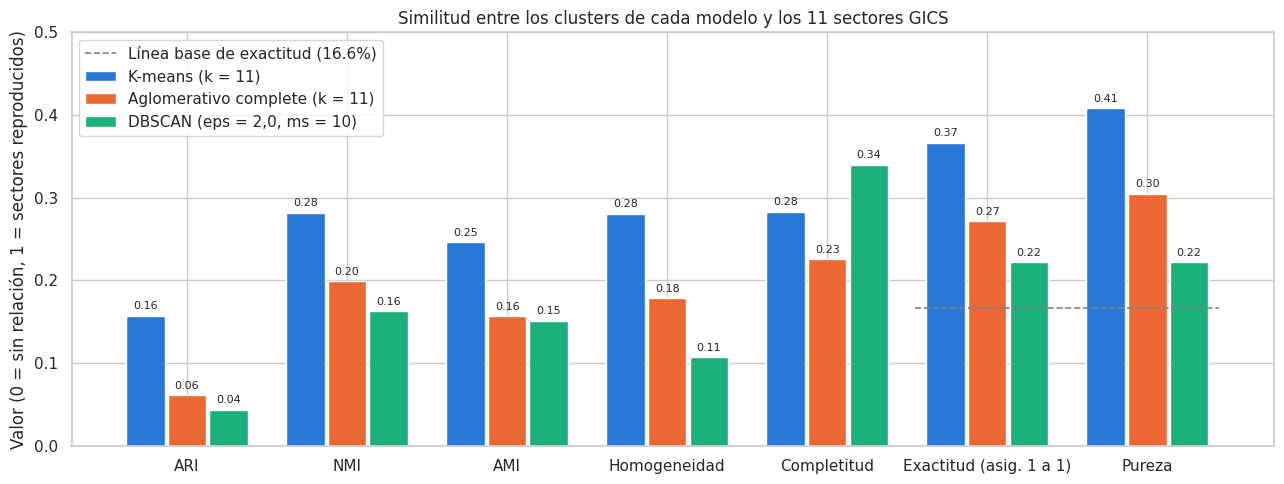

In [ ]:
# Gráfico comparativo de las métricas externas
metricas_plot = ["ARI", "NMI", "AMI", "Homogeneidad", "Completitud", "Exactitud (asig. 1 a 1)", "Pureza"]
colores = ["#2a78d6", "#eb6834", "#1baf7a"]

fig, ax = plt.subplots(figsize=(13, 5))
ancho = 0.26
xpos = np.arange(len(metricas_plot))
for i, (nombre, color) in enumerate(zip(comparacion.index, colores)):
    valores = comparacion.loc[nombre, metricas_plot].values.astype(float)
    barras = ax.bar(xpos + (i - 1) * ancho, valores, width=ancho - 0.02, color=color, label=nombre)
    for b, v in zip(barras, valores):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.008, f"{v:.2f}", ha="center", fontsize=8)

# La línea base solo aplica a las métricas de exactitud y pureza (las dos últimas)
ax.hlines(linea_base, len(metricas_plot) - 2 - 0.45, len(metricas_plot) - 1 + 0.45, color="gray", ls="--", lw=1.2,
          label=f"Línea base de exactitud ({linea_base:.1%})")
ax.set_xticks(xpos)
ax.set_xticklabels(metricas_plot)
ax.set_ylabel("Valor (0 = sin relación, 1 = sectores reproducidos)")
ax.set_title("Similitud entre los clusters de cada modelo y los 11 sectores GICS")
ax.set_ylim(0, max(0.5, comparacion[metricas_plot].values.max() * 1.15))
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

**Resultado de las métricas.** **K-means es el modelo que más se acerca a los sectores GICS** en 6 de las 7 métricas:

- **ARI:** 0,157 frente a 0,061 del aglomerativo y 0,043 de DBSCAN, es decir, 2,6 y 3,7 veces más parecido a los sectores.
- **AMI:** 0,246 frente a 0,156 y 0,151. La ventaja se mantiene al corregir por azar y por número de clusters.
- **Exactitud 1 a 1:** K-means ubica correctamente al 36,6 % de las empresas, frente al 27,1 % del aglomerativo y el 22,2 % de DBSCAN. Los tres superan la línea base de 16,6 %, pero K-means la multiplica por 2,2.
- **Completitud:** es la única métrica que gana DBSCAN (0,340), pero es engañosa: como deja al 76 % de las empresas en un solo grupo, casi ningún sector se divide. Su homogeneidad, la más baja (0,107), muestra que sus grupos mezclan todos los sectores.

**La silueta y las métricas externas ordenan los modelos de forma distinta.** Según la silueta de cada modelo final, el orden sería DBSCAN (silueta de 0,21, calculada sin el ruido), K-means (silueta de 0,176) y aglomerativo (silueta de 0,106); por parecido con los sectores, K-means queda primero. Que los grupos estén bien separados no significa que se parezcan a los sectores.

En términos absolutos, **ningún modelo reproduce los sectores**: un ARI de 0,157 está mucho más cerca de 0 que de 1.

### Tablas de contingencia: cluster frente a sector

Cada fila es un cluster y cada columna un sector. Si un modelo reprodujera los sectores, cada fila tendría una sola celda oscura y cada columna también. Los clusters se ordenan según el sector que les asigna la correspondencia uno a uno, para que una reproducción perfecta se viera como una diagonal.

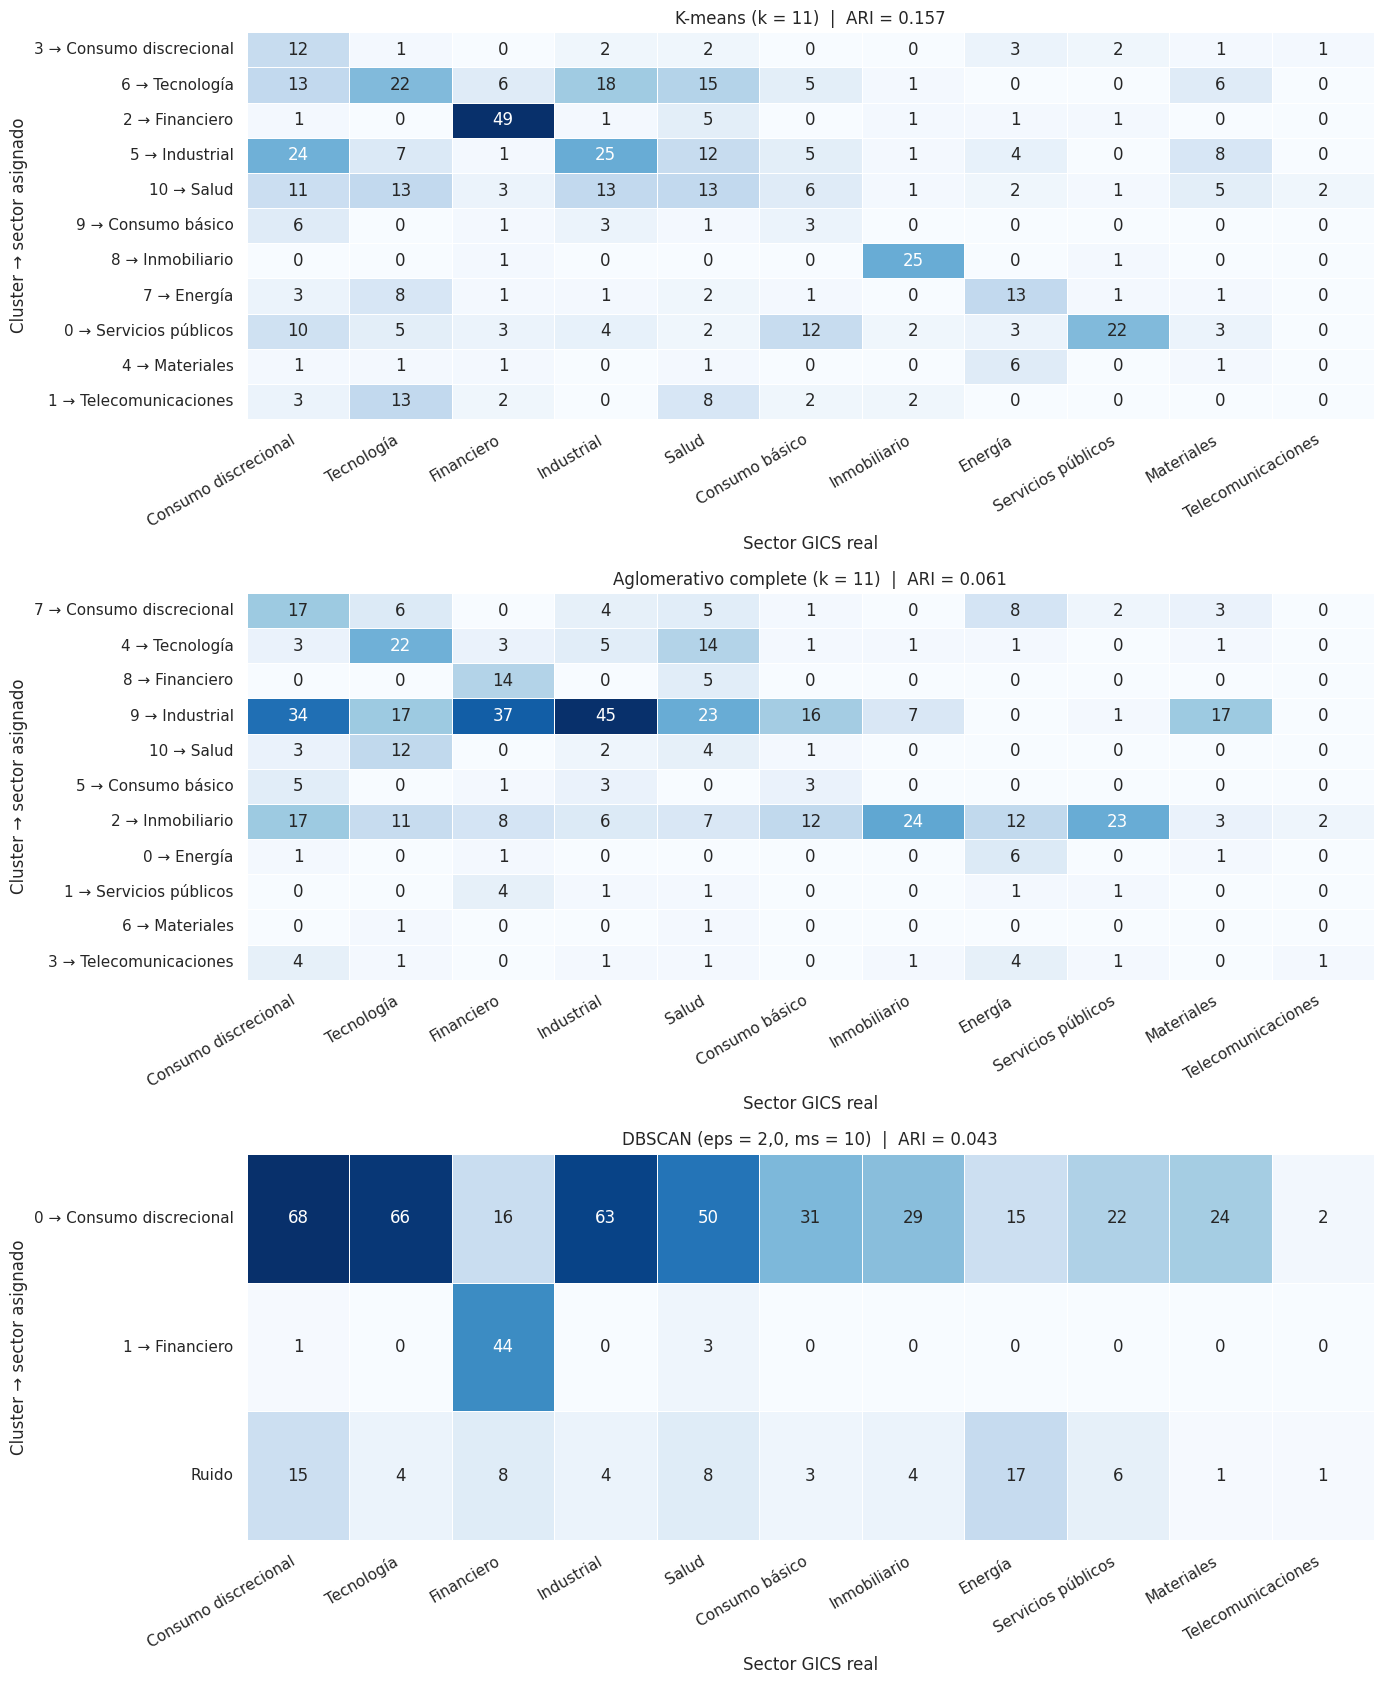

In [ ]:
orden_sectores = y.value_counts().index.tolist()
fig, axes = plt.subplots(3, 1, figsize=(14, 17))

for ax, (nombre, lab) in zip(axes, modelos.items()):
    tabla = pd.crosstab(lab, y)[orden_sectores]
    mapa = mapas[nombre]
    # Orden de filas: primero los clusters asignados, en el orden de los sectores; luego el resto y el ruido
    asignados = sorted(mapa, key=lambda c: orden_sectores.index(mapa[c]))
    resto = [c for c in tabla.index if c not in asignados]
    tabla = tabla.loc[asignados + resto]
    etiquetas_filas = [f"{c} → {etiquetas.get(mapa[c], mapa[c])}" if c in mapa
                       else ("Ruido" if c == -1 else f"{c} (sin asignar)") for c in tabla.index]
    sns.heatmap(tabla, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax, linewidths=0.5,
                yticklabels=etiquetas_filas,
                xticklabels=[etiquetas.get(s, s) for s in orden_sectores])
    ax.set_title(f"{nombre}  |  ARI = {comparacion.loc[nombre, 'ARI']:.3f}")
    ax.set_xlabel("Sector GICS real")
    ax.set_ylabel("Cluster → sector asignado")
    ax.tick_params(axis="x", rotation=30)
    for t in ax.get_xticklabels():
        t.set_ha("right")

plt.tight_layout()
plt.show()

Cada fila es un cluster y cada columna un sector real; el número de cada celda indica cuántas empresas de ese sector cayeron en ese cluster, y el color más oscuro señala más empresas. Si un modelo reprodujera los sectores, se vería una diagonal oscura y el resto en blanco.

**Lectura de las tablas de contingencia.**

- **K-means:** es el único modelo con una diagonal visible. Recupera con claridad **Financiero** (49 empresas en el cluster 2), **Inmobiliario** (25 en el cluster 8) y **Servicios públicos** (22 en el cluster 0), y de forma moderada **Energía** (13 en el cluster 7). Los clusters 9, 4 y 1 se asignan a Consumo básico, Materiales y Telecomunicaciones con solo 3, 1 y 0 aciertos: son asignaciones forzadas por la regla 1 a 1 y en realidad corresponden a grupos de estilo financiero.
- **Aglomerativo:** el cluster 9 absorbe empresas de casi todos los sectores, y el cluster 2 junta Inmobiliario (24) con Servicios públicos (23). Como solo uno de los dos puede quedarse con ese cluster, Servicios públicos termina asignado al cluster 1, con un solo acierto.
- **DBSCAN:** con dos clusters, como máximo dos sectores pueden recibir un grupo. El cluster 1 corresponde a Financiero (44 empresas) y el cluster 0 se asigna a Consumo discrecional solo porque es el sector más grande dentro de una masa que contiene a todos.

### ¿Qué sectores recupera cada modelo?

Para cada sector se busca el cluster que mejor lo representa y se mide con el **F1**, que combina dos preguntas: qué fracción del sector cae en ese cluster (*recall*) y qué fracción del cluster pertenece al sector (*precisión*). Un F1 cercano a 1 significa que existe un cluster que es, prácticamente, ese sector.

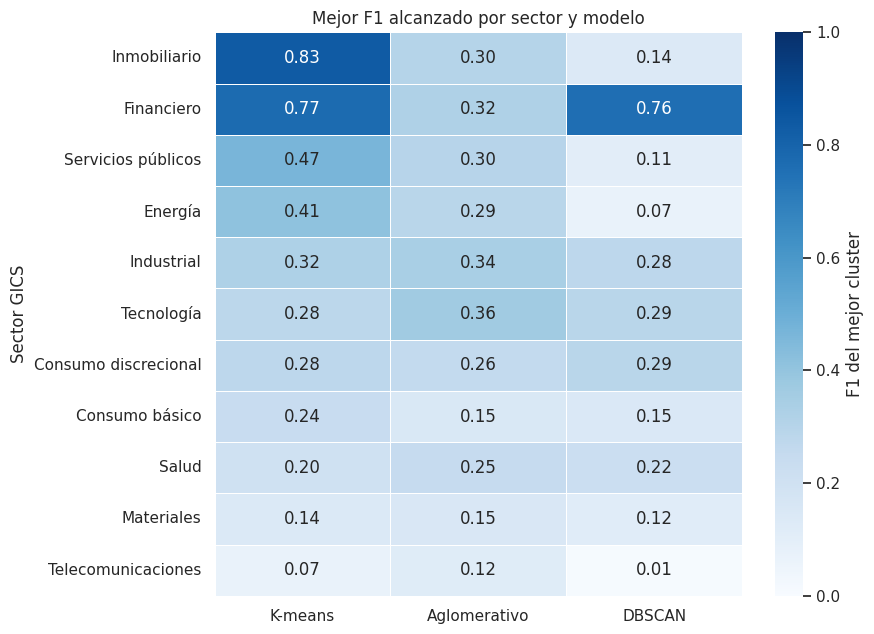

F1 promedio por modelo (todos los sectores con el mismo peso):
K-means (k = 11)                  0.367
Aglomerativo complete (k = 11)    0.260
DBSCAN (eps = 2,0, ms = 10)       0.221


In [ ]:
def mejor_f1_por_sector(labels, y):
    tabla = pd.crosstab(labels, y).drop(index=-1, errors="ignore")
    tam_cluster = tabla.sum(axis=1)
    tam_sector = y.value_counts()
    res = {}
    for s in tabla.columns:
        precision = tabla[s] / tam_cluster
        recall = tabla[s] / tam_sector[s]
        f1 = (2 * precision * recall / (precision + recall)).fillna(0)
        res[s] = f1.max()
    return pd.Series(res)

f1_sectores = pd.DataFrame({nombre: mejor_f1_por_sector(lab, y) for nombre, lab in modelos.items()})
f1_sectores = f1_sectores.loc[f1_sectores.iloc[:, 0].sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(9, 6.5))
nombres_cortos = ["K-means", "Aglomerativo", "DBSCAN"]
sns.heatmap(f1_sectores.set_axis(nombres_cortos, axis=1), annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=ax, linewidths=0.5,
            yticklabels=[etiquetas.get(s, s) for s in f1_sectores.index],
            cbar_kws={"label": "F1 del mejor cluster"})
ax.set_title("Mejor F1 alcanzado por sector y modelo")
ax.set_xlabel("")
ax.set_ylabel("Sector GICS")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

print("F1 promedio por modelo (todos los sectores con el mismo peso):")
print(f1_sectores.mean().round(3).to_string())

**Cómo leer el gráfico.** Cada fila es un sector y cada columna un modelo; el valor es el F1 del cluster que mejor representa a ese sector. Un F1 cercano a 1 indica que existe un cluster que es, prácticamente, ese sector.

**Sectores recuperados por cada modelo.**

- **K-means:** recupera con claridad **Inmobiliario (F1 = 0,83)** y **Financiero (0,77)**, y de forma parcial **Servicios públicos (0,47)** y **Energía (0,41)**. El resto de sectores queda entre 0,07 y 0,32.
- **Aglomerativo:** no supera 0,36 en ningún sector. Aunque es algo mejor que K-means en Tecnología, Industrial y Salud, al juntar Inmobiliario con Servicios públicos y dividir Financiero pierde los sectores que K-means sí identifica.
- **DBSCAN:** iguala a K-means en Financiero (0,76), porque ambos aíslan el mismo grupo de empresas con EBITDA = 0, pero en los demás sectores queda por debajo.

Hay un detalle y es que
- **Telecomunicaciones** (3 empresas) no supera 0,12 en ningún modelo: con tan pocas empresas no puede formar un grupo propio.

El F1 promedio confirma el orden: **K-means 0,367, aglomerativo 0,260 y DBSCAN 0,221**.

Los sectores que K-means recupera son los que el análisis exploratorio identificó con una "huella financiera" distintiva: los REIT por su dividendo alto, los bancos y aseguradoras por su EBITDA = 0, las utilities por su baja volatilidad y las petroleras por sus pérdidas.

### Modelo ganador: correspondencia entre clusters y sectores (K-means)

In [ ]:
mejor = comparacion["ARI"].idxmax()
lab_mejor = modelos[mejor]
tabla = pd.crosstab(lab_mejor, y)

resumen_mejor = pd.DataFrame({
    "Empresas": tabla.sum(axis=1),
    "Sector asignado (1 a 1)": pd.Series(mapas[mejor]),
    "Sector mayoritario": tabla.idxmax(axis=1),
    "% del cluster en su sector mayoritario": (tabla.max(axis=1) / tabla.sum(axis=1) * 100).round(1),
})
resumen_mejor["% del sector capturado"] = [
    round(tabla.loc[c, s] / (y == s).sum() * 100, 1) for c, s in resumen_mejor["Sector mayoritario"].items()
]
resumen_mejor.index.name = "Cluster"
print(f"Modelo con mayor parecido a los sectores GICS: {mejor}\n")
display(resumen_mejor.sort_values("% del cluster en su sector mayoritario", ascending=False))

Modelo con mayor parecido a los sectores GICS: K-means (k = 11)



,Empresas,Sector asignado (1 a 1),Sector mayoritario,% del cluster en su sector mayoritario,% del sector capturado
Cluster,,,,,
8,27,Real Estate,Real Estate,92.6,75.8
2,59,Financials,Financials,83.1,72.1
4,11,Materials,Energy,54.5,18.8
3,24,Consumer Discretionary,Consumer Discretionary,50.0,14.3
1,30,Telecommunication Services,Information Technology,43.3,18.6
9,14,Consumer Staples,Consumer Discretionary,42.9,7.1
7,31,Energy,Energy,41.9,40.6
0,66,Utilities,Utilities,33.3,78.6
5,87,Industrials,Industrials,28.7,37.3


**Correspondencia entre clusters y sectores.**

La tabla cruza dos medidas: el porcentaje del cluster que pertenece a su sector mayoritario (pureza) y el porcentaje del sector que el cluster captura.

- **Clusters 8 y 2:** son los únicos puros y completos a la vez. El cluster 8 es 93 % Real Estate y captura el 76 % del sector; el cluster 2 es 83 % Financials y captura el 72 %.
- **Cluster 0:** captura el 79 % de Utilities, pero solo el 33 % del cluster son utilities, porque las mezcla con otras empresas defensivas.
- **Clusters 4, 1 y 9:** el sector asignado no coincide con su sector mayoritario. Son asignaciones forzadas por la regla 1 a 1.
- **Resto de clusters:** ningún sector supera la mitad del grupo; agrupan empresas por estilo financiero y no por industria.

solo dos clusters son de verdad un sector: el de inmobiliarias y el de financieras

# Conclusión de la comparación

**El modelo que más se acerca a recrear los 11 sectores GICS es K-means con k = 11.**

| Criterio | K-means | Aglomerativo (complete) | DBSCAN |
|---|---|---|---|
| ARI | **0,157** | 0,061 | 0,043 |
| AMI | **0,246** | 0,156 | 0,151 |
| Exactitud (asignación 1 a 1) | **36,6 %** | 27,1 % | 22,2 % |
| F1 promedio por sector | **0,367** | 0,260 | 0,221 |
| Sectores con F1 > 0,5 | Real Estate, Financials | Ninguno | Financials |

**¿Por qué gana K-means?** Es el único que reparte las empresas en 11 grupos de tamaño moderado. El aglomerativo concentra el 64 % de las empresas en dos grupos, y DBSCAN no encuentra más de dos zonas densas.

**¿Qué sectores recupera?**

- **Real Estate y Financials:** con claridad. Cada uno tiene un cluster propio (8 y 2) que es casi puro y captura más del 70 % del sector.
- **Utilities y Energy:** de forma parcial. El cluster 0 captura el 79 % de las utilities y el cluster 7 el 41 % de las petroleras, pero mezcladas con otras empresas.
- **Los demás sectores:** no se recuperan; sus empresas se reparten según su estilo financiero.

**Respuesta a la pregunta de investigación.** Las métricas financieras solo permiten reconstruir los sectores cuyo modelo de negocio deja una huella clara en los estados financieros: los REIT, que reparten la mayor parte de sus utilidades; los bancos y aseguradoras, para los que el EBITDA no aplica; y, en menor medida, las utilities y las petroleras. Para el resto, los algoritmos agrupan por **estilo de inversión** (*growth*, defensivo, megacap, con pérdidas) y no por industria. Por eso, aun el mejor modelo ubica correctamente a menos del 40 % de las empresas.

#Parte 2

###Redes neuronales artificiales y reducción de dimensionalidad

####Selección de caracteristicas

#### Preparación de Datos y Partición de Entrenamiento/Prueba

In [ ]:
# !pip install mlxtend   # si Colab no lo tiene
import time
import keras
from keras.models import Sequential
from keras.layers import Dense
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from mlxtend.feature_selection import SequentialFeatureSelector as SFS
import warnings
warnings.filterwarnings("ignore")

Al realizar la partición del data set se obtuvieron 378 datos para entrenamiento y 127 para prueba

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)

def preparar(d):
    d = d.copy()
    d[cols_log] = d[cols_log].apply(log_signo)
    return d

X_train_t, X_test_t = preparar(X_train), preparar(X_test)
lim_inf, lim_sup = X_train_t.quantile(0.01), X_train_t.quantile(0.99)
X_train_t = X_train_t.clip(lim_inf, lim_sup, axis=1)
X_test_t = X_test_t.clip(lim_inf, lim_sup, axis=1)

scaler = StandardScaler().fit(X_train_t)
X_train_scaled = pd.DataFrame(scaler.transform(X_train_t), columns=X.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test_t), columns=X.columns, index=X_test.index)
print("Entrenamiento:", X_train_scaled.shape, "| Prueba:", X_test_scaled.shape)

Entrenamiento: (378, 9) | Prueba: (127, 9)


#### Selección de Características con SFFS (Sequential Floating Forward Selection)

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

wrappers = {
    "Regresión logística": LogisticRegression(max_iter=5000),
    "Árbol de decisión": DecisionTreeClassifier(max_depth=5, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=6, random_state=42),
}

subconjuntos = {"Todas las características": list(X.columns)}

for nombre, modelo in wrappers.items():
    sffs = SFS(modelo, k_features="best", forward=True, floating=True, scoring="f1_macro", cv=cv, n_jobs=-1)
    sffs.fit(X_train_scaled, y_train)
    subconjuntos["SFFS + " + nombre] = list(sffs.k_feature_names_)
    print(f"SFFS + {nombre}: F1 macro CV del wrapper = {sffs.k_score_:.4f}")

print()
for nombre, variables in subconjuntos.items():
    descartadas = [c for c in X.columns if c not in variables]
    print(f"{nombre} ({len(variables)} variables) | descarta: {descartadas}")

SFFS + Regresión logística: F1 macro CV del wrapper = 0.4237
SFFS + Árbol de decisión: F1 macro CV del wrapper = 0.3475
SFFS + Random Forest: F1 macro CV del wrapper = 0.4249

Todas las características (9 variables) | descarta: []
SFFS + Regresión logística (8 variables) | descarta: ['Price/Earnings']
SFFS + Árbol de decisión (8 variables) | descarta: ['Price/Earnings']
SFFS + Random Forest (6 variables) | descarta: ['Price/Earnings', 'Market Cap', 'Amplitud_52s']


Se aplicó la selección de características con el método wraper, a partir de tres modelos: regresión logística, random forest y árboles de decisión. La regresión logística obtuvo un F1 de 0.4237 con un total de 8 características ( se descartó Price/Earnings). Random forest obtuvo un F1 de 0.4249 con 6 características, en este caso descartó (Price/Earnings, Market Cap y amplitud 52 semanas). Por último, el árbol de decisión obtuvo un F1 macro de 0.3795 con 8 características, descartando Price/Earnings. Los tres métodos coincidieron en descartar Price/Earnings, probablemente por su redundancia con Earnings/Share, Price/Book y Price/Sales, y por el ruido que generan los valores extremos o negativos. El Random Forest logró el mismo rendimiento que la regresión logística con solo 6 variables en lugar de 8, lo que lo convierte en el subconjunto más parsimonioso.



#### Visualización de Variables Seleccionadas por SFFS

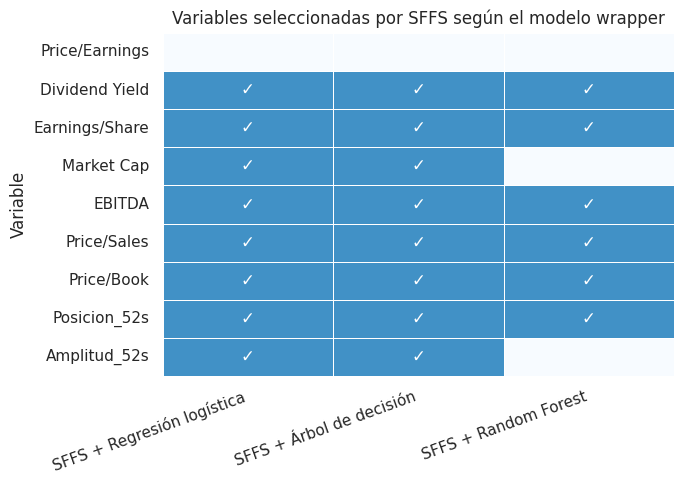

In [ ]:
seleccion = pd.DataFrame(
    {nombre: [c in vars_ for c in X.columns] for nombre, vars_ in subconjuntos.items()
     if nombre != "Todas las características"},
    index=X.columns
)

plt.figure(figsize=(7, 5))
sns.heatmap(seleccion.astype(int), annot=seleccion.replace({True: "✓", False: ""}), fmt="",
            cmap="Blues", cbar=False, linewidths=0.5, vmin=0, vmax=1.6)
plt.title("Variables seleccionadas por SFFS según el modelo wrapper")
plt.xlabel("")
plt.ylabel("Variable")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()


El mapa de calor muestra, para cada variable, si fue seleccionada (casilla azul con ) o descartada (casilla clara) por cada combinación SFFS + modelo. Se observa una tendencia estable de seis variables elegidas por los tres modelos: Dividend Yield, Earnings/Share, EBITDA, Price/Sales, Price/Book y Posicion_52s, lo que sugiere que son las más informativas para diferenciar sectores (por ejemplo, el dividend yield separa sectores de altos dividendos como Utilities o Real Estate de los de bajos dividendos como Tecnología). Price/Earnings aparece vacía en las tres columnas, confirmando que ningún modelo la consideró útil. Las únicas diferencias están en Market Cap y Amplitud_52s, que la regresión logística y el árbol retienen pero el Random Forest descarta, lo que indica que su aporte es marginal o redundante con otras variables (como EBITDA y Posicion_52s). En conjunto, la imagen evidencia que los tres métodos convergen en gran medida y que las diferencias entre subconjuntos son pequeñas


#### Codificación One-Hot de la Variable de Salida (Sectores)

In [ ]:
codificador = OneHotEncoder(sparse_output=False)
Y_train = codificador.fit_transform(y_train.values.reshape(-1, 1))
Y_test = codificador.transform(y_test.values.reshape(-1, 1))
clases = codificador.categories_[0]
print("Y_train:", Y_train.shape, "| Y_test:", Y_test.shape)

Y_train: (378, 11) | Y_test: (127, 11)


#### Definición de la Arquitectura y Función de la Red Neuronal

In [ ]:
def red_neuronal(variables, n1, n2, activacion, epocas):
    tiempo_i = time.time()
    Xv = X_train_scaled[variables].values
    Accuracy = np.zeros(5)
    F1 = np.zeros(5)

    kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    j = 0
    for train_index, test_index in kf.split(Xv, y_train):
        X_tr, X_va = Xv[train_index], Xv[test_index]
        Y_tr, Y_va = Y_train[train_index], Y_train[test_index]

        keras.utils.set_random_seed(j)
        model = Sequential()
        model.add(keras.Input(shape=(len(variables),)))
        model.add(Dense(n1, activation=activacion))
        if n2 > 0:
            model.add(Dense(n2, activation=activacion))
        model.add(Dense(11, activation="softmax"))

        model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3),
                      loss=keras.losses.CategoricalCrossentropy(),
                      metrics=[keras.metrics.CategoricalAccuracy()])

        model.fit(X_tr, Y_tr, epochs=epocas, batch_size=32, verbose=0)

        y_pred = model.predict(X_va, verbose=0)
        real, pred = np.argmax(Y_va, axis=1), np.argmax(y_pred, axis=1)
        Accuracy[j] = accuracy_score(real, pred)
        F1[j] = f1_score(real, pred, average="macro", zero_division=0)
        j += 1

    tiempo = time.time() - tiempo_i
    print("Eficiencia en la clasificación: " + str(np.mean(Accuracy)) + " +/- " + str(np.std(Accuracy)))
    print("F1 macro: " + str(np.mean(F1)) + " +/- " + str(np.std(F1)))
    print("Tiempo total de ejecución: " + str(tiempo) + " segundos.")
    return np.mean(Accuracy), np.std(Accuracy), np.mean(F1), np.std(F1), tiempo

#### Evaluación de Línea Base (Todas las Características)

In [ ]:
red_neuronal(subconjuntos["Todas las características"], n1=32, n2=0, activacion="sigmoid", epocas=50)

Eficiencia en la clasificación: 0.4337894736842106 +/- 0.054712725231401554
F1 macro: 0.322884116008234 +/- 0.048726244184658395
Tiempo total de ejecución: 45.9325590133667 segundos.


(np.float64(0.4337894736842106),
 np.float64(0.054712725231401554),
 np.float64(0.322884116008234),
 np.float64(0.048726244184658395),
 45.9325590133667)

Se aplicó one-hot encoding a la variable objetivo para convertir los 11 sectores en vectores binarios, compatibles con la capa de salida softmax. Luego se llamó a la función de la red neuronal con el subconjunto de todas las características: una entrada de 9 variables, una capa oculta de 32 neuronas con activación sigmoide, una capa de salida de 11 neuronas con softmax, entrenada durante 50 épocas

F1 macro unos pocos sectores (probablemente los más grandes o con perfil distintivo) y mal en los pequeños, que tratan igual en la métrica macro. Sugiere desbalance de clases
Los resultados muestran que la red neuronal base, con todas las características, obtuvo un F1 macro de 0.32 ± 0.05, inferior al de los modelos más simples evaluados durante SFFS (≈ 0.42). Esto sugiere que, con pocos datos y una arquitectura sencilla, la red no ofrece ventaja sobre la regresión logística o el Random Forest.


Luego, evaluamos cual era la mejor combinación para la red neuronal cambiando el número de épocas, capas ocultas y función de activación.

### Tabla 1.A, Variación del número de épocas y la segunda capa oculta. Funcion de activación ReLU

<table>
  <tr>
    <th># de Epocas</th>
    <th># Neuronas en 1ra capa oculta</th>
    <th># Neuronas en 2da capa oculta</th>
    <th>Eficiencia +/- IC</th>
    <th>Tiempo de ejecución (S)</th>
  </tr>
  <tr><td>50</td><td>32</td><td>N/A</td><td>0.4551578947368421 +/- 0.05719713686343018</td><td>35.11788773536682</td></tr>
  
  <tr><td>100</td><td>32</td><td>N/A</td><td>0.46308771929824555 +/- 0.05139717343152021</td><td>74.10014486312866</td></tr>
  
  <tr><td>200</td><td>32</td><td>N/A</td><td>0.46578947368421053 +/- 0.055446812626795024</td><td>82.24671578407288</td></tr>
  
  <tr><td>50</td><td>32</td><td>16</td><td>0.4418947368421053 +/- 0.04248822913780046
</td><td>27.805339097976685</td></tr>
  
  <tr><td>100</td><td>32</td><td>16</td><td>0.4655438596491228 +/- 0.04411833886204047</td><td>50.672619581222534</td></tr>
  
  <tr><td>200</td><td>32</td><td>16</td><td>0.46031578947368423 +/- 0.0438728962450708</td><td>87.68446612358093</td></tr>

</table>

Se evidencia que entre más épocas se entrena la red, mejor clasifica, sin embargo se demora más. Con una capa oculta la eficiencia se mantiene en valores de 0.45 a 0.46. Ahora, al agregar una segunda capa oculta se evidencia una mejoría notable frente, la eficiencia logra  posicionarse en 0.46, sin embargo se obtiene en un tiempo elevado. En este caso, el resultado con una segunda capa resulta más favorable y por ende se recomienda esperar el tiempo de ejecución con el objetivo de obtener una buena clasificación del sector.


### Tabla 1.B, Variación del número de épocas y la segunda capa oculta. Funcion de activación Sigmoide

<table>
  <tr>
    <th># de Epocas</th>
    <th># Neuronas en 1ra capa oculta</th>
    <th># Neuronas en 2da capa oculta</th>
    <th>Eficiencia +/- IC</th>
    <th>Tiempo de ejecución (S)</th>
  </tr>
  <tr><td>50</td><td>32</td><td>N/A</td><td>0.4337894736842106 +/- 0.054712725231401554</td><td>28.058870792388916</td></tr>

  <tr><td>100</td><td>32</td><td>N/A</td><td>0.46031578947368423 +/- 0.04638078905220965</td><td>49.10091948509216</td></tr>
  
  <tr><td>200</td><td>32</td><td>N/A</td><td> 0.4577543859649123 +/- 0.03319887933970252</td><td>83.3479437828064</td></tr>
  
  <tr><td>50</td><td>32</td><td>16</td><td>0.35961403508771933 +/- 0.030869696059577775</td><td>30.72142720222473</td></tr>
  
  <tr><td>100</td><td>32</td><td>16</td><td>0.4497894736842105 +/- 0.0515675366301591</td><td>56.68744707107544</td></tr>
  
  <tr><td>200</td><td>32</td><td>16</td><td>0.49743859649122807 +/- 0.050956332882972175</td><td>85.07854628562927</td></tr>
</table>


Se evidencia que entre más épocas se entrena la red, mejor clasifica, sin embargo se
demora más. Con una capa oculta la eficiencia se mantiene en valores de 0.43 a 0.45. Ahora, al agregar una segunda capa oculta se evidencia una mejoría notable, la eficiencia logra  posicionarse en 0.49, sin embargo se obtiene en un tiempo elevado. En este caso, el resultado con una segunda capa resulta más favorable y por ende se recomienda esperar el tiempo de ejecución con el objetivo de obtener una buena clasificación del sector.


Al probar distintas épocas capas y funciones se concluye que la mejor combinación es una red neuronal con función de activación sigmoidal, 32 neuronas en la primera capa y 16 neuronas en la segunda capa.mejor clasificación, conviene usar 50 épocas. Como se trata de diagnosticar el estado de un feto, vale la pena esperar un poco más para equivocarse menos.



#### Entrenamiento y Validación Cruzada de los Subconjuntos de SFFS

Ahora lo que se hace es probar con la red neuronal elegida, los tres subconjuntos brindados anteriormente con cada modelo; regresión logística, árboles de decisión y random forest, y a su vez, de manera complementaria realiza la prueba con todas las características.


In [ ]:
N1, N2, ACTIVACION, EPOCAS = 32, 16, "sigmoid", 200     # red elegida en las Tablas 1 y 2

filas, probabilidades = [], {}
for nombre, variables in subconjuntos.items():
    print("\n" + nombre)
    acc_cv, ic_acc, f1_cv, ic_f1, tiempo = red_neuronal(variables, N1, N2, ACTIVACION, EPOCAS)

    # Modelo final: se entrena con todo el entrenamiento y se evalúa en prueba
    keras.utils.set_random_seed(42)
    model = Sequential()
    model.add(keras.Input(shape=(len(variables),)))
    model.add(Dense(N1, activation=ACTIVACION))
    if N2 > 0:
        model.add(Dense(N2, activation=ACTIVACION))
    model.add(Dense(11, activation="softmax"))
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3),
                  loss=keras.losses.CategoricalCrossentropy(),
                  metrics=[keras.metrics.CategoricalAccuracy()])
    model.fit(X_train_scaled[variables].values, Y_train, epochs=EPOCAS, batch_size=32, verbose=0)

    P = model.predict(X_test_scaled[variables].values, verbose=0)   # probabilidades de los 11 sectores
    probabilidades[nombre] = P
    real_test, pred_test = np.argmax(Y_test, axis=1), np.argmax(P, axis=1)

    filas.append({"Reducción": nombre, "N° variables": len(variables),
                  "F1 macro CV": f1_cv, "IC F1": ic_f1,
                  "Eficiencia CV": acc_cv, "IC eficiencia": ic_acc,
                  "F1 macro prueba": f1_score(real_test, pred_test, average="macro", zero_division=0),
                  "Accuracy prueba": accuracy_score(real_test, pred_test),
                  "Tiempo (s)": tiempo})

results = pd.DataFrame(filas)
display(results.round(4))


Todas las características
Eficiencia en la clasificación: 0.49743859649122807 +/- 0.050956332882972175
F1 macro: 0.41396973123397884 +/- 0.05950524365523468
Tiempo total de ejecución: 80.5788185596466 segundos.

SFFS + Regresión logística
Eficiencia en la clasificación: 0.48157894736842105 +/- 0.0411011858615342
F1 macro: 0.40297608303503274 +/- 0.05806374084111474
Tiempo total de ejecución: 86.89904999732971 segundos.

SFFS + Árbol de decisión
Eficiencia en la clasificación: 0.48157894736842105 +/- 0.0411011858615342
F1 macro: 0.40297608303503274 +/- 0.05806374084111474
Tiempo total de ejecución: 81.24749946594238 segundos.

SFFS + Random Forest
Eficiencia en la clasificación: 0.44207017543859645 +/- 0.05166187390274495
F1 macro: 0.3586401406391414 +/- 0.0685879432078608
Tiempo total de ejecución: 79.62482857704163 segundos.


,Reducción,N° variables,F1 macro CV,IC F1,Eficiencia CV,IC eficiencia,F1 macro prueba,Accuracy prueba,Tiempo (s)
0,Todas las características,9,0.4140,0.0595,0.4974,0.0510,0.3823,0.4173,80.5788
1,SFFS + Regresión logística,8,0.4030,0.0581,0.4816,0.0411,0.3615,0.4016,86.8990
2,SFFS + Árbol de decisión,8,0.4030,0.0581,0.4816,0.0411,0.3615,0.4016,81.2475
3,SFFS + Random Forest,6,0.3586,0.0686,0.4421,0.0517,0.3826,0.4252,79.6248


Los resultados no permiten identificar un subconjunto claramente superior: con todas las variables se obtiene el mejor desempeño en validación cruzada (F1 macro 0.414), mientras que el subconjunto de Random Forest, con 6 variables, iguala o supera ligeramente en prueba (F1 macro 0.383 vs. 0.382). Dado que las diferencias son menores que los intervalos de confianza y el ranking cambia según la métrica, se concluye que son estadísticamente equivalentes. Por parsimonia, se prefiere el subconjunto de 6 variables, que logra un desempeño comparable con menor complejidad.

#### Comparación Gráfica del Rendimiento (CV vs. Prueba)

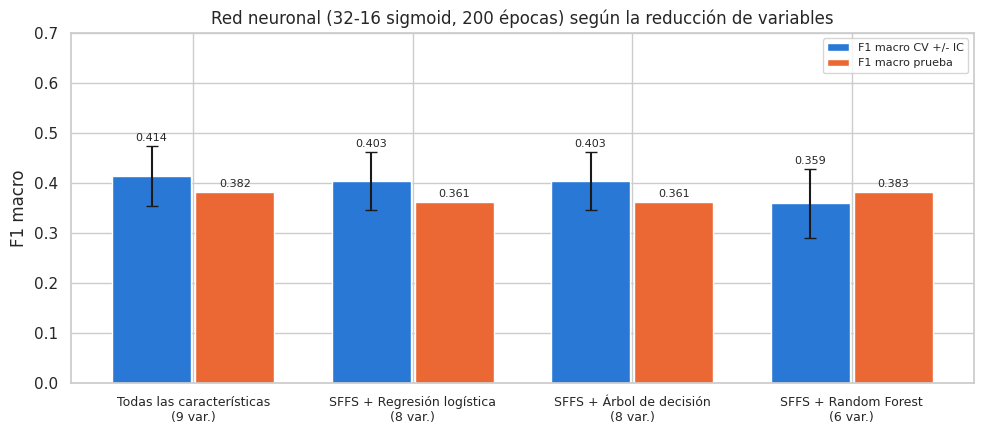

In [ ]:
fig, ax = plt.subplots(figsize=(10, 4.5))
xpos, ancho = np.arange(len(results)), 0.38
b1 = ax.bar(xpos - ancho / 2, results["F1 macro CV"], ancho - 0.02, yerr=results["IC F1"], capsize=4,
            color="#2a78d6", label="F1 macro CV +/- IC")
b2 = ax.bar(xpos + ancho / 2, results["F1 macro prueba"], ancho - 0.02, color="#eb6834", label="F1 macro prueba")
for b, e in zip(b1, results["IC F1"]):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + e + 0.01, f"{b.get_height():.3f}", ha="center", fontsize=8)
for b in b2:
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.01, f"{b.get_height():.3f}", ha="center", fontsize=8)
ax.set_xticks(xpos)
ax.set_xticklabels([f"{r}\n({n} var.)" for r, n in zip(results["Reducción"], results["N° variables"])], fontsize=9)
ax.set_ylabel("F1 macro")
ax.set_ylim(0, 0.7)
ax.set_title(f"Red neuronal ({N1}-{N2} {ACTIVACION}, {EPOCAS} épocas) según la reducción de variables")
ax.legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.show()

La gráfica muestra que el F1 macro de la red neuronal se mantiene en un rango similar (0.36-0.41) sin importar el subconjunto de variables. En validación cruzada, el mejor resultado corresponde a todas las características (0.414) En el conjunto de prueba, el subconjunto de Random Forest (6 variables) iguala a todas las características (0.383 vs. 0.382). En conjunto, esto indica que es posible reducir de 9 a 6 variables sin deterioro apreciable del desempeño, lo que favorece el modelo más parsimonioso.


#### Reporte de Clasificación y Matriz de Confusión del Mejor Modelo

Mejor reducción: Todas las características
Variables: ['Price/Earnings', 'Dividend Yield', 'Earnings/Share', 'Market Cap', 'EBITDA', 'Price/Sales', 'Price/Book', 'Posicion_52s', 'Amplitud_52s']

                            precision    recall  f1-score   support

    Consumer Discretionary       0.36      0.43      0.39        21
          Consumer Staples       1.00      0.44      0.62         9
                    Energy       0.44      0.50      0.47         8
                Financials       0.90      0.53      0.67        17
               Health Care       0.33      0.07      0.11        15
               Industrials       0.14      0.24      0.17        17
    Information Technology       0.38      0.61      0.47        18
                 Materials       0.00      0.00      0.00         6
               Real Estate       0.64      0.88      0.74         8
Telecommunication Services       0.00      0.00      0.00         1
                 Utilities       0.57      0.57      0.5

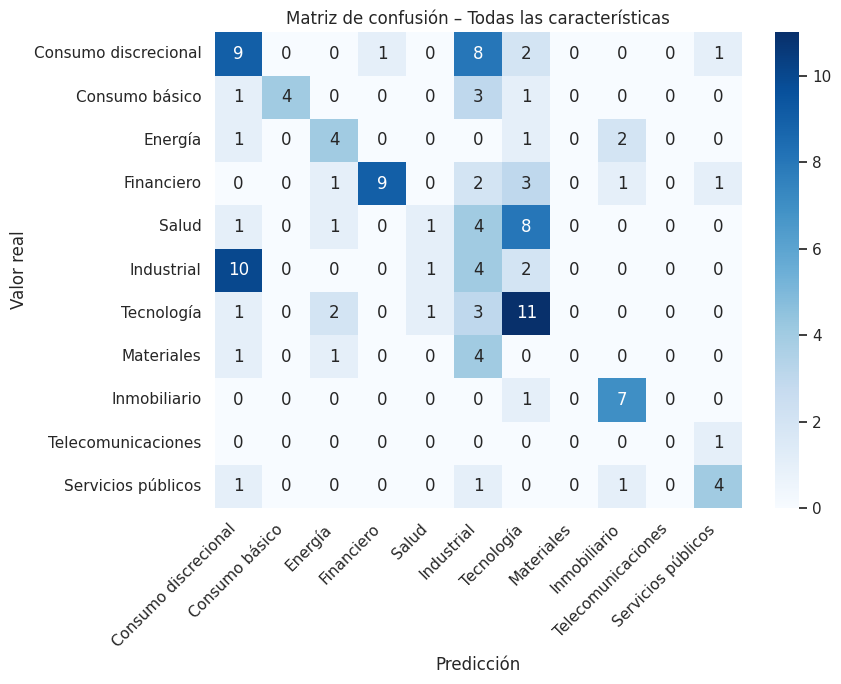

In [ ]:
best_method = results.sort_values("Eficiencia CV", ascending=False).iloc[0]["Reducción"]
P_best = probabilidades[best_method]
pred_best = clases[np.argmax(P_best, axis=1)]

print("Mejor reducción:", best_method)
print("Variables:", subconjuntos[best_method])
print()
print(classification_report(y_test, pred_best, zero_division=0))

nombres = [etiquetas.get(c, c) for c in clases]
cm = confusion_matrix(y_test, pred_best, labels=clases)
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=nombres, yticklabels=nombres)
plt.xlabel("Predicción")
plt.ylabel("Valor real")
plt.title(f"Matriz de confusión – {best_method}")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

l resultado indica que la mejor reducción es: ninguna, teniendo en cuenta este tipo de neurona. Se obtienen mejores resultados con todas las variables.

Las variables que el modelo logra discriminar mejor son:

Real Estate (Inmobiliario): con un recall 0.88, F1 0.74. De 8 empresas, clasifica bien 7. Este sector tiene un perfil muy particular (dividend yield alto, estructura tipo REIT).
Financials: con un F1 0.67, precisión 0.90. El modelo casi nunca confunde otro sector con financiero, aunque pierde algunas (recall 0.53).
Consumer Staples y Utilities: con un F1 0.62 y 0.57. Los dividendos y la estabilidad los hacen reconocibles. Consumer Staples tiene precisión 1.00 pero recall 0.44: cuando predice ese sector acierta, pero deja pasar más de la mitad.
Las variables que el modelo no logra discriminar bien son:
Industrials (F1 0.17): de 17 empresas, 10 fueron clasificadas como Consumer Discretionary. Es la confusión más fuerte de la matriz.
Health Care (F1 0.11): solo 1 de 15 acertada; 8 fueron a Tecnología y 4 a Industrial. Tiene sentido: biotecnología y tecnología comparten perfiles de alto crecimiento, bajo dividendo y múltiplos elevados.
Materials (F1 0.00): ninguna acertada (4 de 6 fueron a Industrial).
Telecommunications (F1 0.00): sólo hay 1 empresa en prueba, así que esa métrica no es interpretable.

Esto se da puesto que el modelo confunde sectores con indicadores financieros muy similares, tales como: consumo discrecional,  Industrial, Salud y Tecnología. Los múltiplos financieros no capturan la naturaleza del negocio, sólo su valoración, por eso sectores distintos pero con valoraciones similares se mezclan.

El mal desempeño de la F1 es causado por el mal desempeño de los pequeños sectores, puesto que al tener tan pocas muestras, el modelo no logra aprender un patrón. A su vez, sus indicadores financieros no muestran un comportamiento muy marcado, por eso, es fácil que el modelo confunda los sectores.

La matriz de confusión muestra que los aciertos se concentran en sectores con perfil financiero distintivo, como Inmobiliario (7 de 8) y Financiero (9 de 17). Los errores se concentran en parejas de sectores con valoraciones similares: 10 empresas industriales fueron clasificadas como consumo discrecional y 8 de salud como tecnología. Materiales y Telecomunicaciones prácticamente no se identifican, lo que evidencia que los indicadores de valoración no bastan para distinguir sectores heterogéneos o con pocos ejemplos

#### Análisis de Errores: Distribución de Predicciones por Sector

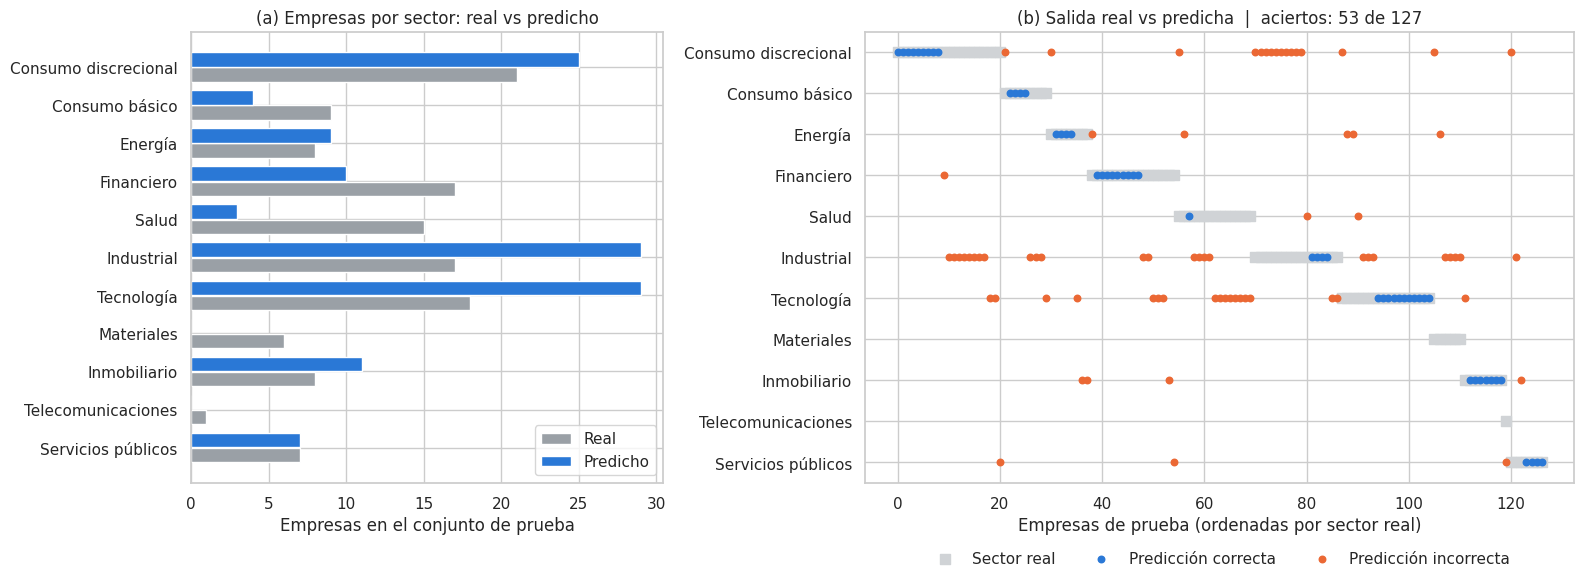

In [ ]:
real_idx = np.argmax(Y_test, axis=1)
pred_idx = np.argmax(P_best, axis=1)
acierto = real_idx == pred_idx
ypos = np.arange(len(clases))

fig, axes = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={"width_ratios": [1, 1.5]})

# (a) Empresas por sector: real vs predicho
n_real = np.bincount(real_idx, minlength=len(clases))
n_pred = np.bincount(pred_idx, minlength=len(clases))
axes[0].barh(ypos + 0.2, n_real, 0.38, color="#9aa0a6", label="Real")
axes[0].barh(ypos - 0.2, n_pred, 0.38, color="#2a78d6", label="Predicho")
axes[0].set_yticks(ypos)
axes[0].set_yticklabels(nombres)
axes[0].invert_yaxis()
axes[0].set_xlabel("Empresas en el conjunto de prueba")
axes[0].set_title("(a) Empresas por sector: real vs predicho")
axes[0].legend()

# (b) Empresa por empresa: sector real (cuadro gris) y predicho (punto)
orden = np.lexsort((pred_idx, real_idx))
x = np.arange(len(orden))
axes[1].scatter(x, real_idx[orden], marker="s", s=60, color="#d0d3d6", label="Sector real")
axes[1].scatter(x[acierto[orden]], pred_idx[orden][acierto[orden]], s=22, color="#2a78d6", label="Predicción correcta")
axes[1].scatter(x[~acierto[orden]], pred_idx[orden][~acierto[orden]], s=22, color="#eb6834", label="Predicción incorrecta")
axes[1].set_yticks(ypos)
axes[1].set_yticklabels(nombres)
axes[1].invert_yaxis()
axes[1].set_xlabel("Empresas de prueba (ordenadas por sector real)")
axes[1].set_title(f"(b) Salida real vs predicha  |  aciertos: {acierto.sum()} de {len(acierto)}")
axes[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3, frameon=False)
plt.tight_layout()
plt.show()

La gráfica muestra que la red sobrepredice los sectores Industrial, Tecnología y Consumo discrecional (29, 29 y 25 predicciones frente a 17, 18 y 21 empresas reales) y subpredice Salud, Financiero y Consumo básico; Materiales y Telecomunicaciones nunca son predichos. El panel (b) confirma que solo 53 de las 127 empresas fueron clasificadas correctamente y que los errores se concentran en la asignación de empresas de otros sectores a las categorías amplias. Esto indica que la red tiende a refugiarse en los sectores más grandes o de perfil más genérico, y que los indicadores de valoración no son suficientes para identificar sectores pequeños o heterogéneos

##Reducción de dimensión con PCA y LDA

Con SFFS se redujo la dimensión eligiendo algunas de las variables originales. Con PCA y LDA se reduce de otra forma: se crean variables nuevas que combinan las 9 originales, y se conservan solo las más útiles.

•	PCA crea las variables nuevas sin mirar el sector. Busca las combinaciones que resumen la mayor parte de las diferencias entre empresas.

•	LDA sí usa el sector. Busca las combinaciones que mejor separan un sector de otro.

Para comparar con SFFS en igualdad de condiciones, se usa la misma red neuronal elegida antes (32 y 16 neuronas, activación sigmoide, 200 épocas) y el mismo criterio de selección, el F1 macro. Con cada técnica se prueban de 1 a 9 dimensiones para responder con cuántas se obtienen los mejores resultados.


In [ ]:
from mlxtend.feature_extraction import PrincipalComponentAnalysis
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

# Etiquetas numéricas (0 a 10) para LDA, en el mismo orden de las salidas de la red
y_train_num = np.argmax(Y_train, axis=1)
y_test_num = np.argmax(Y_test, axis=1)

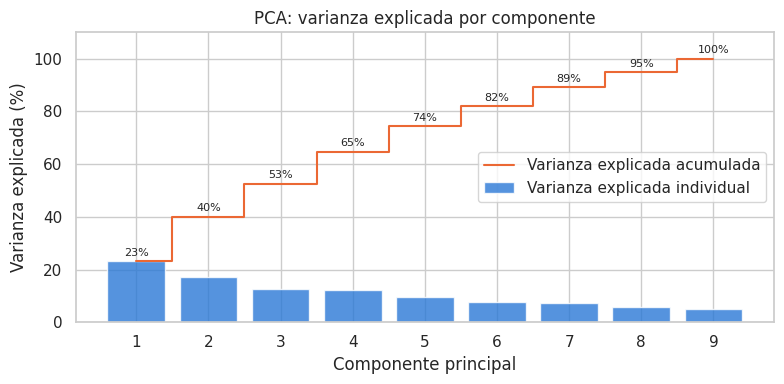

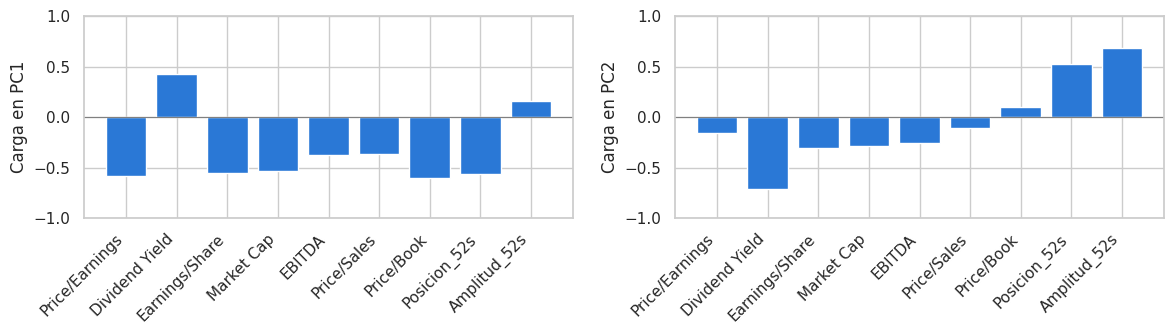

In [ ]:
pca = PrincipalComponentAnalysis(n_components=None)
pca.fit(X_train_scaled.values)

var_exp = pca.e_vals_normalized_ * 100
cum_var_exp = np.cumsum(var_exp)

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(range(1, 10), var_exp, color="#2a78d6", alpha=0.8, label="Varianza explicada individual")
ax.step(range(1, 10), cum_var_exp, where="mid", color="#eb6834", label="Varianza explicada acumulada")
for i, v in enumerate(cum_var_exp):
    ax.text(i + 1, v + 2, f"{v:.0f}%", ha="center", fontsize=8)
ax.set_xlabel("Componente principal")
ax.set_ylabel("Varianza explicada (%)")
ax.set_xticks(range(1, 10))
ax.set_ylim(0, 110)
ax.set_title("PCA: varianza explicada por componente")
ax.legend(loc="center right")
plt.tight_layout()
plt.show()

# Cargas (loadings) de las dos primeras componentes: qué variables pesan en cada una
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
for i in range(2):
    ax[i].bar(range(9), pca.loadings_[:, i], color="#2a78d6")
    ax[i].set_xticks(range(9))
    ax[i].set_xticklabels(X_train_scaled.columns, rotation=45, ha="right")
    ax[i].set_ylabel(f"Carga en PC{i + 1}")
    ax[i].set_ylim(-1, 1)
    ax[i].axhline(0, color="gray", lw=0.8)
plt.tight_layout()
plt.show()

La información está muy repartida entre las componentes: la primera explica solo el 23 % de las diferencias entre empresas, las dos primeras el 40 %, y se necesitan 6 componentes para llegar al 80 %. Es decir, PCA no puede resumir los datos en pocas variables nuevas sin perder mucha información. Esto ocurre porque las 9 variables miden cosas distintas y casi no se repiten entre sí. las que sí se repetían y podrían haber sido descartadas por PCA ya se habían eliminado en la Parte 1.

Las cargas permiten darles un significado financiero a las dos primeras:

•	PC 1: puede interpretarse como un eje de favorabilidad del mercado. En el lado negativo quedan las empresas que el mercado premia: grandes, rentables, con múltiplos altos y precio cerca de su máximo anual. En el lado positivo quedan las empresas que el mercado castiga: con pérdidas, más volátiles y con precio cerca de su mínimo, junto con empresas de dividendo alto que estaban a la baja en ese momento, como las utilities. Este eje refleja la situación de cada empresa en el momento de la recolección de los datos y no depende del sector, ya que en cada extremo hay empresas de sectores diferentes.

•	PC 2: Esta componente está dominada por dos variables opuestas: el dividend yield y la amplitud del precio en 52 semanas. En el lado negativo quedan las empresas defensivas de renta, que pagan buen dividendo y tienen un precio estable. En el lado positivo quedan las empresas volátiles que pagan poco o ningún dividendo. Es una medida de perfil de riesgo: renta estable frente a volatilidad. Agrupa a los sectores defensivos, pero no los distingue entre sí, y además separa empresas de un mismo sector.

Las dos componentes describen estilos de inversión, no sectores: dentro de un mismo sector hay empresas de crecimiento y de generación de valor. Por eso se espera que PCA tenga dificultades para separar los sectores con pocas dimensiones.


##Metodologia de linear discriminant analysis (LDA)

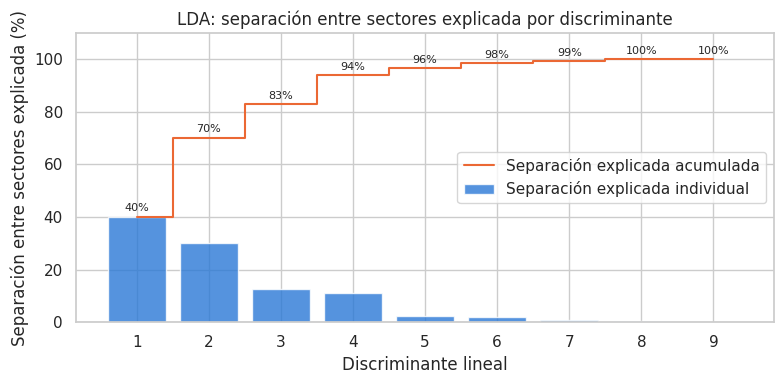

In [ ]:
lda = LinearDiscriminantAnalysis()
lda.fit(X_train_scaled.values, y_train_num)

disc_exp = lda.explained_variance_ratio_ * 100
cum_disc_exp = np.cumsum(disc_exp)

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(range(1, len(disc_exp) + 1), disc_exp, color="#2a78d6", alpha=0.8, label="Separación explicada individual")
ax.step(range(1, len(disc_exp) + 1), cum_disc_exp, where="mid", color="#eb6834", label="Separación explicada acumulada")
for i, v in enumerate(cum_disc_exp):
    ax.text(i + 1, v + 2, f"{v:.0f}%", ha="center", fontsize=8)
ax.set_xlabel("Discriminante lineal")
ax.set_ylabel("Separación entre sectores explicada (%)")
ax.set_xticks(range(1, len(disc_exp) + 1))
ax.set_ylim(0, 110)
ax.set_title("LDA: separación entre sectores explicada por discriminante")
ax.legend(loc="center right")
plt.tight_layout()
plt.show()

A diferencia de PCA, la separación entre sectores que encuentra LDA se concentra en pocos discriminantes. El primero explica el 40% de la separación y el segundo un 30% adicional, así que con solo dos dimensiones ya se recoge el 70%. Con el tercero se llega al 83% y con el cuarto al 94%. A partir del quinto, cada discriminante aporta menos del 3%, y del séptimo en adelante el aporte es prácticamente nulo.

Esto significa que LDA puede resumir en 4 dimensiones casi toda la información que sirve para distinguir un sector de otro. El 94% se refiere a la separación entre sectores, no a toda la información de los datos: lo que LDA descarta en los últimos discriminantes son diferencias entre empresas que no ayudan a identificar su sector.

La diferencia con PCA se explica porque LDA usa la variable Sector para construir sus ejes: busca directamente las combinaciones de variables que alejan a los sectores entre sí. PCA, en cambio, no conoce los sectores y necesitaba 6 componentes para conservar el 80% de la varianza. Por eso se espera que, con pocas dimensiones, la red neuronal clasifique mejor con LDA que con PCA. Esta hipótesis se comprueba más adelante con el F1 de la red para cada dimensión.


In [ ]:
def red_neuronal_reduccion(metodo, k, n1, n2, activacion, epocas):
    tiempo_i = time.time()
    Xv = X_train_scaled.values
    Accuracy = np.zeros(5)
    F1 = np.zeros(5)

    kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    j = 0
    for train_index, test_index in kf.split(Xv, y_train):
        X_tr, X_va = Xv[train_index], Xv[test_index]
        Y_tr, Y_va = Y_train[train_index], Y_train[test_index]

        # Reducción de dimensión (ajustada solo con el entrenamiento del fold)
        if metodo == "PCA":
            reductor = PrincipalComponentAnalysis(n_components=k)
            reductor.fit(X_tr)
        else:
            reductor = LinearDiscriminantAnalysis(n_components=k)
            reductor.fit(X_tr, y_train_num[train_index])
        X_tr, X_va = reductor.transform(X_tr), reductor.transform(X_va)

        keras.utils.set_random_seed(j)
        model = Sequential()
        model.add(keras.Input(shape=(k,)))
        model.add(Dense(n1, activation=activacion))
        if n2 > 0:
            model.add(Dense(n2, activation=activacion))
        model.add(Dense(11, activation="softmax"))

        model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3),
                      loss=keras.losses.CategoricalCrossentropy(),
                      metrics=[keras.metrics.CategoricalAccuracy()])

        model.fit(X_tr, Y_tr, epochs=epocas, batch_size=32, verbose=0)

        y_pred = model.predict(X_va, verbose=0)
        real, pred = np.argmax(Y_va, axis=1), np.argmax(y_pred, axis=1)
        Accuracy[j] = accuracy_score(real, pred)
        F1[j] = f1_score(real, pred, average="macro", zero_division=0)
        j += 1

    tiempo = time.time() - tiempo_i
    print(f"{metodo} con {k} dimensiones -> F1 macro: {np.mean(F1):.4f} +/- {np.std(F1):.4f} | "
          f"Eficiencia: {np.mean(Accuracy):.4f} +/- {np.std(Accuracy):.4f} | Tiempo: {tiempo:.1f} s")
    return np.mean(Accuracy), np.std(Accuracy), np.mean(F1), np.std(F1), tiempo

In [ ]:
# Misma red elegida en la seleccion de la red neuronal optima.
dimensiones = range(1, 10)

filas = []
for metodo in ["PCA", "LDA"]:
    for k in dimensiones:
        acc_cv, ic_acc, f1_cv, ic_f1, tiempo = red_neuronal_reduccion(metodo, k, N1, N2, ACTIVACION, EPOCAS)
        filas.append({"Método": metodo, "Dimensión": k, "F1 macro CV": f1_cv, "IC F1": ic_f1,
                      "Eficiencia CV": acc_cv, "IC eficiencia": ic_acc, "Tiempo (s)": tiempo})

resultados_dim = pd.DataFrame(filas)
display(resultados_dim.round(4))

PCA con 1 dimensiones -> F1 macro: 0.0939 +/- 0.0198 | Eficiencia: 0.1852 +/- 0.0255 | Tiempo: 136.8 s
PCA con 2 dimensiones -> F1 macro: 0.1829 +/- 0.0518 | Eficiencia: 0.2488 +/- 0.0580 | Tiempo: 77.9 s
PCA con 3 dimensiones -> F1 macro: 0.3078 +/- 0.0535 | Eficiencia: 0.3995 +/- 0.0551 | Tiempo: 79.5 s
PCA con 4 dimensiones -> F1 macro: 0.3476 +/- 0.0715 | Eficiencia: 0.4366 +/- 0.0433 | Tiempo: 76.0 s
PCA con 5 dimensiones -> F1 macro: 0.3633 +/- 0.0611 | Eficiencia: 0.4419 +/- 0.0496 | Tiempo: 74.1 s
PCA con 6 dimensiones -> F1 macro: 0.3630 +/- 0.0762 | Eficiencia: 0.4446 +/- 0.0552 | Tiempo: 74.4 s
PCA con 7 dimensiones -> F1 macro: 0.3768 +/- 0.0627 | Eficiencia: 0.4656 +/- 0.0463 | Tiempo: 73.0 s
PCA con 8 dimensiones -> F1 macro: 0.3913 +/- 0.0625 | Eficiencia: 0.4763 +/- 0.0462 | Tiempo: 73.4 s
PCA con 9 dimensiones -> F1 macro: 0.4088 +/- 0.0671 | Eficiencia: 0.4895 +/- 0.0510 | Tiempo: 74.0 s
LDA con 1 dimensiones -> F1 macro: 0.1636 +/- 0.0492 | Eficiencia: 0.2700 +/- 0.0

,Método,Dimensión,F1 macro CV,IC F1,Eficiencia CV,IC eficiencia,Tiempo (s)
0,PCA,1,0.0939,0.0198,0.1852,0.0255,136.8116
1,PCA,2,0.1829,0.0518,0.2488,0.0580,77.8994
2,PCA,3,0.3078,0.0535,0.3995,0.0551,79.5442
3,PCA,4,0.3476,0.0715,0.4366,0.0433,76.0496
4,PCA,5,0.3633,0.0611,0.4419,0.0496,74.1461
5,PCA,6,0.3630,0.0762,0.4446,0.0552,74.3892
6,PCA,7,0.3768,0.0627,0.4656,0.0463,72.9575
7,PCA,8,0.3913,0.0625,0.4763,0.0462,73.4418
8,PCA,9,0.4088,0.0671,0.4895,0.0510,74.0307
9,LDA,1,0.1636,0.0492,0.2700,0.0341,79.1010


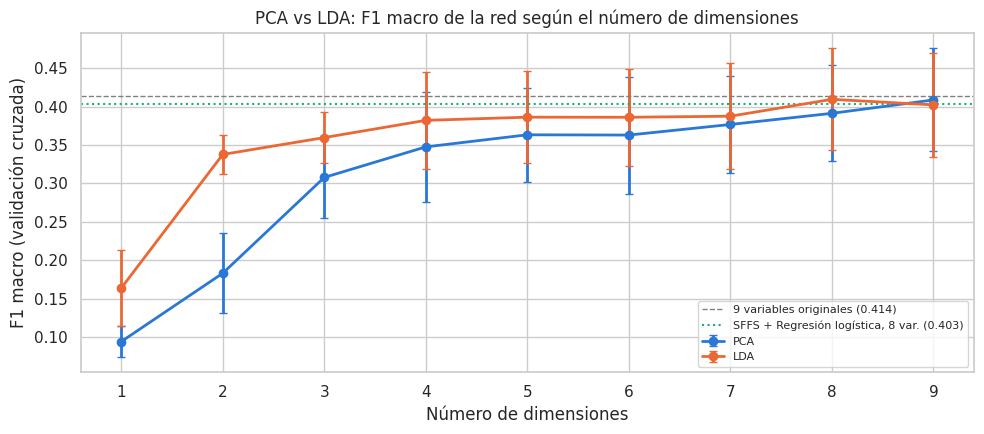

Mejor dimensión de cada método (según F1 macro CV):


,Método,Dimensión,F1 macro CV,IC F1,Eficiencia CV,IC eficiencia,Tiempo (s)
16,LDA,8,0.4096,0.0666,0.4816,0.0481,69.9998
8,PCA,9,0.4088,0.0671,0.4895,0.0510,74.0307


In [ ]:
f1_todas = results.loc[results["Reducción"] == "Todas las características", "F1 macro CV"].iloc[0]
mejor_sffs = results[results["Reducción"] != "Todas las características"].sort_values("F1 macro CV", ascending=False).iloc[0]

fig, ax = plt.subplots(figsize=(10, 4.5))
for metodo, color in [("PCA", "#2a78d6"), ("LDA", "#eb6834")]:
    sub = resultados_dim[resultados_dim["Método"] == metodo]
    ax.errorbar(sub["Dimensión"], sub["F1 macro CV"], yerr=sub["IC F1"], marker="o", ms=6, lw=2,
                capsize=3, color=color, label=metodo)
ax.axhline(f1_todas, color="gray", ls="--", lw=1, label=f"9 variables originales ({f1_todas:.3f})")
ax.axhline(mejor_sffs["F1 macro CV"], color="#1baf7a", ls=":", lw=1.5,
           label=f"{mejor_sffs['Reducción']}, {mejor_sffs['N° variables']} var. ({mejor_sffs['F1 macro CV']:.3f})")
ax.set_xlabel("Número de dimensiones")
ax.set_ylabel("F1 macro (validación cruzada)")
ax.set_xticks(list(dimensiones))
ax.set_title("PCA vs LDA: F1 macro de la red según el número de dimensiones")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

mejores_dim = resultados_dim.loc[resultados_dim.groupby("Método")["F1 macro CV"].idxmax()]
print("Mejor dimensión de cada método (según F1 macro CV):")
display(mejores_dim.round(4))

Los resultados confirman lo que anticipaban las gráficas de varianza y separación explicada: con pocas dimensiones, la red clasifica mucho mejor con LDA que con PCA. Con 2 dimensiones, LDA obtiene un F1 macro de 0,338 frente a 0,183 de PCA, y LDA supera a PCA en todas las dimensiones de 1 a 8. Esto se debe a la naturaleza de cada técnica: LDA usa el sector para construir sus ejes y concentra en los primeros discriminantes la información que separa los sectores, mientras que PCA no conoce los sectores y sus primeras componentes resumen diferencias entre empresas, como el estilo de inversión o el perfil de riesgo, que no sirven para identificar el sector.

¿Cuál debo elegir entonces? Se eligen ambos modelos, cada uno con su mejor dimensión según el F1 macro en validación cruzada: PCA con 9 componentes (F1 de 0,409) y LDA con 8 discriminantes (F1 de 0,410), como se puede ver en validación cruzada son estadísticamente equivalentes. Hay que tener en cuenta que el modelo de PCA con 9 componentes no reduce la dimensión, porque conserva toda la información de las variables originales, y que LDA ofrece además una alternativa más compacta: con 4 discriminantes alcanza un F1 de 0,382, un desempeño relativamente parecido con muchas menos dimensiones que también se podría contemplar aplicar.


###Comparación de las tecnicas de reducción

In [ ]:
filas, predicciones_red = [], {}
for _, r in mejores_dim.iterrows():
    metodo, k = r["Método"], int(r["Dimensión"])
    if metodo == "PCA":
        reductor = PrincipalComponentAnalysis(n_components=k)
        reductor.fit(X_train_scaled.values)
    else:
        reductor = LinearDiscriminantAnalysis(n_components=k)
        reductor.fit(X_train_scaled.values, y_train_num)
    Z_train, Z_test = reductor.transform(X_train_scaled.values), reductor.transform(X_test_scaled.values)

    keras.utils.set_random_seed(42)
    model = Sequential()
    model.add(keras.Input(shape=(k,)))
    model.add(Dense(N1, activation=ACTIVACION))
    if N2 > 0:
        model.add(Dense(N2, activation=ACTIVACION))
    model.add(Dense(11, activation="softmax"))
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3),
                  loss=keras.losses.CategoricalCrossentropy(),
                  metrics=[keras.metrics.CategoricalAccuracy()])
    model.fit(Z_train, Y_train, epochs=EPOCAS, batch_size=32, verbose=0)

    pred = np.argmax(model.predict(Z_test, verbose=0), axis=1)
    predicciones_red[metodo] = pred
    filas.append({"Reducción": f"{metodo} ({k} dim.)", "N° variables": k,
                  "F1 macro CV": r["F1 macro CV"], "IC F1": r["IC F1"],
                  "Eficiencia CV": r["Eficiencia CV"], "IC eficiencia": r["IC eficiencia"],
                  "F1 macro prueba": f1_score(y_test_num, pred, average="macro", zero_division=0),
                  "Accuracy prueba": accuracy_score(y_test_num, pred), "Tiempo (s)": r["Tiempo (s)"]})

# Tabla final: las 9 variables, la mejor selección de SFFS, PCA y LDA
comparacion = pd.concat([results[results["Reducción"] == "Todas las características"],
                         results[results["Reducción"] == mejor_sffs["Reducción"]],
                         pd.DataFrame(filas)], ignore_index=True)
display(comparacion.round(4))

,Reducción,N° variables,F1 macro CV,IC F1,Eficiencia CV,IC eficiencia,F1 macro prueba,Accuracy prueba,Tiempo (s)
0,Todas las características,9,0.4140,0.0595,0.4974,0.0510,0.3823,0.4173,80.5788
1,SFFS + Regresión logística,8,0.4030,0.0581,0.4816,0.0411,0.3615,0.4016,86.8990
2,LDA (8 dim.),8,0.4096,0.0666,0.4816,0.0481,0.3642,0.4016,69.9998
3,PCA (9 dim.),9,0.4088,0.0671,0.4895,0.0510,0.3538,0.3858,74.0307


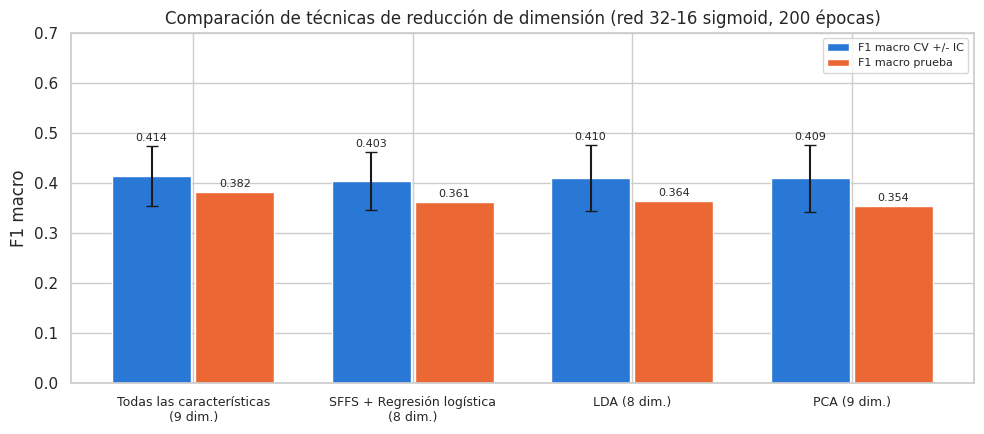

In [ ]:
fig, ax = plt.subplots(figsize=(10, 4.5))
xpos, ancho = np.arange(len(comparacion)), 0.38
b1 = ax.bar(xpos - ancho / 2, comparacion["F1 macro CV"], ancho - 0.02, yerr=comparacion["IC F1"], capsize=4,
            color="#2a78d6", label="F1 macro CV +/- IC")
b2 = ax.bar(xpos + ancho / 2, comparacion["F1 macro prueba"], ancho - 0.02, color="#eb6834", label="F1 macro prueba")
for b, e in zip(b1, comparacion["IC F1"]):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + e + 0.01, f"{b.get_height():.3f}", ha="center", fontsize=8)
for b in b2:
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.01, f"{b.get_height():.3f}", ha="center", fontsize=8)
ax.set_xticks(xpos)
ax.set_xticklabels([f"{r}\n({n} dim.)" if "dim." not in r else r
                    for r, n in zip(comparacion["Reducción"], comparacion["N° variables"])], fontsize=9)
ax.set_ylabel("F1 macro")
ax.set_ylim(0, 0.7)
ax.set_title(f"Comparación de técnicas de reducción de dimensión (red {N1}-{N2} {ACTIVACION}, {EPOCAS} épocas)")
ax.legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.show()

Las cuatro alternativas obtienen prácticamente el mismo F1 macro en validación cruzada (entre 0,403 y 0,414), con diferencias mucho menores que su IC (±0,06 a ±0,07). En prueba se mantiene el mismo orden: las 9 variables originales clasifican correctamente 53 de las 127 empresas, SFFS y LDA 51 y PCA 49. Todos los modelos bajan entre 3 y 6 puntos en prueba frente a la validación cruzada, lo que es esperable porque su configuración se eligió como la mejor entre muchas opciones evaluadas en esos mismos folds.

Las 9 variables originales son la mejor alternativa, aunque su ventaja no es significativa. Ninguna reducción mejora la red porque, desde la Parte 1, las variables redundantes ya se habían eliminado. Entre las técnicas de reducción, LDA obtiene el mayor F1 en validación cruzada y empata con SFFS en prueba, mientras que PCA obtiene el resultado más bajo en prueba y, al usar sus 9 componentes, no reduce la dimensión.


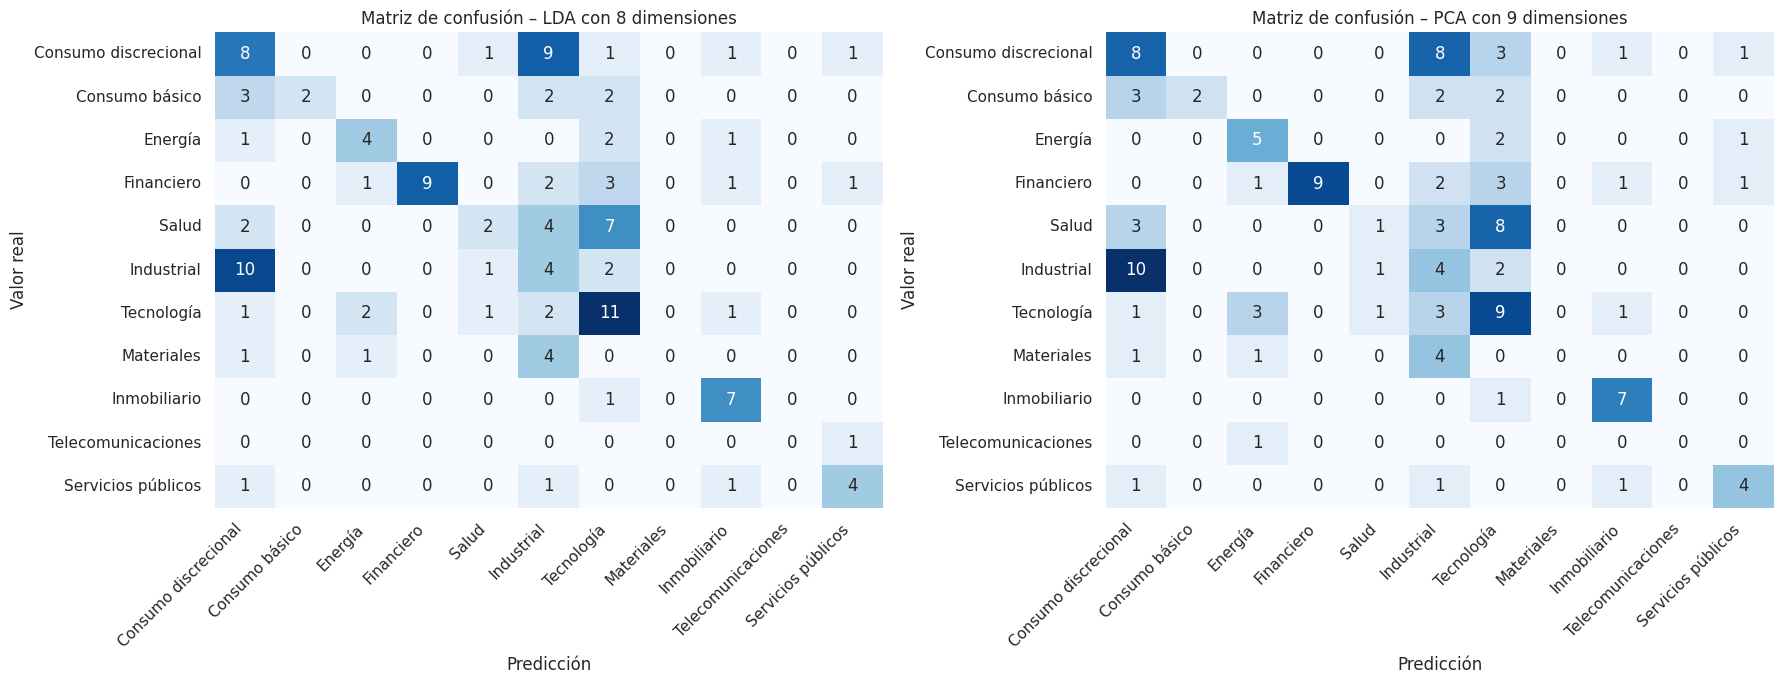


LDA
                            precision    recall  f1-score   support

    Consumer Discretionary       0.30      0.38      0.33        21
          Consumer Staples       1.00      0.22      0.36         9
                    Energy       0.50      0.50      0.50         8
                Financials       1.00      0.53      0.69        17
               Health Care       0.40      0.13      0.20        15
               Industrials       0.14      0.24      0.18        17
    Information Technology       0.38      0.61      0.47        18
                 Materials       0.00      0.00      0.00         6
               Real Estate       0.58      0.88      0.70         8
Telecommunication Services       0.00      0.00      0.00         1
                 Utilities       0.57      0.57      0.57         7

                  accuracy                           0.40       127
                 macro avg       0.44      0.37      0.36       127
              weighted avg       0.47    

In [ ]:
nombres = [etiquetas.get(c, c) for c in clases]
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
for ax, (metodo, pred) in zip(axes, predicciones_red.items()):
    k = int(mejores_dim.loc[mejores_dim["Método"] == metodo, "Dimensión"].iloc[0])
    cm = confusion_matrix(y_test_num, pred, labels=range(len(clases)))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=nombres, yticklabels=nombres, ax=ax, cbar=False)
    ax.set_xlabel("Predicción")
    ax.set_ylabel("Valor real")
    ax.set_title(f"Matriz de confusión – {metodo} con {k} dimensiones")
    ax.tick_params(axis="x", rotation=45)
    for t in ax.get_xticklabels():
        t.set_ha("right")
plt.tight_layout()
plt.show()

for metodo, pred in predicciones_red.items():
    print(f"\n{metodo}")
    print(classification_report(y_test_num, pred, labels=range(len(clases)), target_names=list(clases), zero_division=0))

Matrices de confusión y reporte de clasificación. LDA y PCA tienen un desempeño casi idéntico: accuracy de 0,40 y 0,39, F1 macro de 0,36 y 0,35, y cometen prácticamente los mismos errores. Esto indica que el límite está en los datos y no en la técnica de reducción. Los dos modelos reconocen bien los sectores con una huella financiera distintiva: Inmobiliario identifica 7 de sus 8 empresas (recall de 0,88), y Financiero y Consumo básico tienen una precisión de 1,00 (cuando el modelo los predice, siempre acierta), aunque dejan por fuera a buena parte de sus empresas.

Los errores se concentran en sectores con perfiles financieros parecidos: 10 de las 17 empresas industriales se clasifican como consumo discrecional y viceversa, y la mitad de las empresas de salud se clasifican como tecnología, por lo que tecnología recoge a muchas empresas que no son suyas (precisión de 0,30 a 0,38). Materiales y Telecomunicaciones nunca se predicen.

Esto explica que el F1 macro sea menor que el ponderado (0,36 frente a 0,39 en LDA): al darle el mismo peso a cada sector, el F1 macro penaliza que el modelo ignore los sectores pequeños, y por eso es el criterio adecuado para comparar los modelos.


#Conclusiones finales

Al inicio del trabajo se planteó si las métricas financieras y de valoración, por sí solas, contienen suficiente información para reconstruir los sectores económicos. Los resultados muestran que no la contienen por completo.

En la Parte 1, el mejor modelo de clustering (K-means) solo se parece parcialmente a la clasificación GICS (ARI de 0,164), y en la Parte 2 la mejor red neuronal clasifica correctamente 53 de las 127 empresas de prueba. Este resultado está lejos de una clasificación confiable. Las métricas financieras solo identifican bien los sectores con una huella propia: Inmobiliario, por su dividendo alto; Financiero, por su EBITDA igual a 0; y Servicios públicos, por su estabilidad. Para los demás, empresas de sectores distintos tienen perfiles financieros parecidos, y empresas de un mismo sector tienen perfiles muy diferentes.

Las técnicas de reducción de dimensión no mejoraron la clasificación, porque las 9 variables ya eran poco redundantes, pero cada una aporta información distinta. SFFS permite identificar qué variables son más útiles para distinguir sectores y mostró que el P/E puede eliminarse sin perder desempeño. LDA es la técnica más adecuada si el objetivo es clasificar el sector con pocas dimensiones, porque concentra en sus primeros ejes la información que separa los sectores. PCA, en cambio, no sirve para predecir el sector, pero sus componentes revelan otra estructura en los datos: ordenan a las empresas según cómo las valora el mercado y según su perfil de riesgo, separando a las empresas defensivas de renta estable de las volátiles.

Esto confirma la hipótesis alternativa planteada al inicio: aunque no reproducen la clasificación GICS, las métricas financieras permiten construir una segmentación alternativa basada en el perfil financiero de las empresas, como la de los clústeres de K-means o los ejes de PCA. Esta segmentación es útil para problemas donde importa más el comportamiento financiero que la industria, por ejemplo, identificar empresas refugio frente a empresas volátiles en la gestión de riesgo de un portafolio, o escoger comparables para una valoración según su perfil y no solo según su sector.

